# Section 1 - Data Analysis

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from src.data_preprocessing import *
import warnings
warnings.filterwarnings("ignore")


In [2]:
df_raw = pd.read_csv("datasets/EVChargingStationUsage.csv")
df_raw.head(2)

,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,...,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284.0,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,...,-122.160309,USD,0.0,Customer,4,94301.0,4169.0,NaN,NaN,NaN


## Preprocessing and cleaning 

In [3]:
initial_length = len(df_raw)
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 259415 entries, 0 to 259414
Data columns (total 33 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Station Name                     259415 non-null  str    
 1   MAC Address                      259415 non-null  str    
 2   Org Name                         259415 non-null  str    
 3   Start Date                       259415 non-null  str    
 4   Start Time Zone                  259415 non-null  str    
 5   End Date                         259415 non-null  str    
 6   End Time Zone                    259415 non-null  str    
 7   Transaction Date (Pacific Time)  259206 non-null  str    
 8   Total Duration (hh:mm:ss)        259415 non-null  str    
 9   Charging Time (hh:mm:ss)         259415 non-null  str    
 10  Energy (kWh)                     259415 non-null  float64
 11  GHG Savings (kg)                 259415 non-null  float64
 12  Gasoline Savi

In [4]:
df = preprocess(df_raw)

df.head(10)

[IDs -> strings]
[parse dates, drop invalid]
  dropped 249 rows with invalid or missing dates
[drop non-USD sessions and redundant columns]
  dropped 14 rows with currency MXN, EUR, CAD
  dropped columns: ['Country', 'Plug Type', 'Org Name', 'Currency', 'City', 'State/Province']
[clean station names]
[clean addresses]
[normalize MAC addresses]
[fill EVSE ID / Model Number from MAC]
  EVSE ID: filled 57,688 of 78,927 missing, 21,239 still missing
  Model Number: filled 57,688 of 78,927 missing, 21,239 still missing
[drop System S/N]
[fill missing categoricals with 'missing']
[add UTC columns]
[drop time zone mismatches]
  dropped 120 rows where start and end time zones are different
[validate durations and build duration columns]
  dropped 347 rows with missing or inconsistent duration (difference > 60 s)
[add time features]
[check Start <= End]
  OK: no rows with Start Date later than End Date
[remove outliers]
Sessions kept: 256,643 of 258,685 (failed plug-ins removed: 2,024, impossib

,Station Name,MAC Address,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),Energy (kWh),...,total_duration_hours,charging_duration_hours,idle_seconds,idle_hours,start_hour,time_of_day,year,month,day_of_week,site
0,HAMILTON 1,000D6F00015A9D76,2011-07-29 20:17:00,PDT,2011-07-29 23:20:00,PDT,2011-07-29 23:20:00,3:03:32,1:54:03,6.249457,...,3.058889,1.900833,4169.0,1.158056,20,Evening,2011,7,4,HAMILTON
1,HAMILTON 1,000D6F00015A9D76,2011-07-30 00:00:00,PDT,2011-07-30 00:02:00,PDT,2011-07-30 00:02:00,0:02:06,0:01:54,0.106588,...,0.035000,0.031667,12.0,0.003333,0,Night,2011,7,5,HAMILTON
2,HAMILTON 1,000D6F00015A9D76,2011-07-30 08:16:00,PDT,2011-07-30 12:34:00,PDT,2011-07-30 12:34:00,4:17:32,4:17:28,14.951777,...,4.292222,4.291111,4.0,0.001111,8,Morning,2011,7,5,HAMILTON
3,HAMILTON 1,000D6F00015A9D76,2011-07-30 14:51:00,PDT,2011-07-30 16:55:00,PDT,2011-07-30 16:55:00,2:03:24,2:02:58,7.159643,...,2.056667,2.049444,26.0,0.007222,14,Afternoon,2011,7,5,HAMILTON
4,HAMILTON 1,000D6F00015A9D76,2011-07-30 18:51:00,PDT,2011-07-30 20:03:00,PDT,2011-07-30 20:03:00,1:11:24,0:43:54,1.957765,...,1.190000,0.731667,1650.0,0.458333,18,Evening,2011,7,5,HAMILTON
5,HAMILTON 1,000D6F00015A9D76,2011-07-30 21:38:00,PDT,2011-07-31 01:30:00,PDT,2011-07-31 01:30:00,3:52:13,1:30:58,4.802880,...,3.870278,1.516111,8475.0,2.354167,21,Evening,2011,7,5,HAMILTON
6,HAMILTON 1,000D6F00015A9D76,2011-07-31 04:33:00,PDT,2011-07-31 10:40:00,PDT,2011-07-31 10:40:00,6:06:19,4:56:47,17.171463,...,6.105278,4.946389,4172.0,1.158889,4,Night,2011,7,6,HAMILTON
7,HAMILTON 1,000D6F00015A9D76,2011-07-31 12:25:00,PDT,2011-07-31 13:35:00,PDT,2011-07-31 13:35:00,1:09:54,1:09:49,3.799148,...,1.165000,1.163611,5.0,0.001389,12,Afternoon,2011,7,6,HAMILTON
8,HAMILTON 1,000D6F00015A9D76,2011-07-31 17:41:00,PDT,2011-07-31 22:31:00,PDT,2011-07-31 22:31:00,4:49:46,4:41:16,16.238552,...,4.829444,4.687778,510.0,0.141667,17,Afternoon,2011,7,6,HAMILTON
9,HAMILTON 1,000D6F00015A9D76,2011-08-01 19:11:00,PDT,2011-08-01 22:34:00,PDT,2011-08-01 22:34:00,3:23:34,1:35:08,5.041244,...,3.392778,1.585556,6506.0,1.807222,19,Evening,2011,8,0,HAMILTON


### Do stations change address or location over time?

Some stations appear under more than one `Address 1` and more than one `Latitude`/`Longitude` pair. Here we check whether these changes happen at specific dates, which would mean the station was moved or its record was updated, or whether the values are mixed throughout, which would mean inconsistent data entry.

In [5]:
def period_pattern(g: pd.DataFrame) -> str:
    """'one value', 'changed over time' (each period starts after the previous one ends) or 'mixed' (periods overlap)."""
    if len(g) == 1:
        return 'one value'
    g = g.sort_values('first')
    overlaps = (g['first'].iloc[1:].values < g['last'].iloc[:-1].values).any()
    return 'mixed (overlapping periods)' if overlaps else 'changed over time'


# stations that appear under more than one address
addr_per_station = df.groupby('Station Name')['Address 1'].nunique()
multi_addr = addr_per_station[addr_per_station > 1].index
print("Stations with more than one address:", list(multi_addr))

# when each station used each address
addr_periods = (
    df[df['Station Name'].isin(multi_addr)]
    .groupby(['Station Name', 'Address 1'])['Start Date']
    .agg(first='min', last='max', sessions='count')
    .reset_index()
    .sort_values(['Station Name', 'first'])
)
addr_pattern = addr_periods.groupby('Station Name').apply(period_pattern, include_groups=False).rename('pattern')
display(addr_periods.merge(addr_pattern, on='Station Name'))

Stations with more than one address: ['CAMBRIDGE 1', 'CAMBRIDGE 2', 'RINCONADA LIB 1', 'RINCONADA LIB 2', 'RINCONADA LIB 3', 'WEBSTER 1', 'WEBSTER 2', 'WEBSTER 3']


,Station Name,Address 1,first,last,sessions,pattern
0,CAMBRIDGE 1,400 Cambridge Ave,2016-01-14 11:19:00,2018-03-12 13:35:00,6421,changed over time
1,CAMBRIDGE 1,475 Cambridge Ave,2018-03-12 14:51:00,2020-12-31 06:50:00,4649,changed over time
2,CAMBRIDGE 2,400 Cambridge Ave,2016-01-14 13:45:00,2018-03-12 14:20:00,6104,changed over time
3,CAMBRIDGE 2,475 Cambridge Ave,2018-03-12 15:26:00,2020-12-29 09:06:00,3055,changed over time
4,RINCONADA LIB 1,1520 Walnut Dr,2015-01-02 10:01:00,2016-06-22 15:34:00,2069,changed over time
5,RINCONADA LIB 1,1213 Newell Rd,2016-06-22 18:16:00,2020-07-02 08:56:00,4105,changed over time
6,RINCONADA LIB 2,1520 Walnut Dr,2015-01-02 08:43:00,2016-06-22 15:25:00,1758,changed over time
7,RINCONADA LIB 2,1213 Newell Rd,2016-06-22 18:34:00,2020-07-05 13:17:00,3736,changed over time
8,RINCONADA LIB 3,1514 Walnut Dr,2015-01-02 17:08:00,2016-06-22 15:13:00,2160,changed over time
9,RINCONADA LIB 3,1213 Newell Rd,2016-06-22 17:35:00,2020-07-04 19:06:00,4297,changed over time


In [6]:
# sessions per year for each station and address
display(
    df[df['Station Name'].isin(multi_addr)]
    .groupby(['Station Name', 'Address 1', df['Start Date'].dt.year.rename('year')])
    .size()
    .unstack(fill_value=0)
)

year                                2015  2016  2017  2018  2019  2020
Station Name    Address 1                                             
CAMBRIDGE 1     400 Cambridge Ave      0  2908  2996   517     0     0
                475 Cambridge Ave      0     0     0  1368  2114  1167
CAMBRIDGE 2     400 Cambridge Ave      0  2828  2786   490     0     0
                475 Cambridge Ave      0     0     0  1071  1360   624
RINCONADA LIB 1 1213 Newell Rd         0   966  1470   621   805   243
                1520 Walnut Dr      1309   760     0     0     0     0
RINCONADA LIB 2 1213 Newell Rd         0   874  1355   572   746   189
                1520 Walnut Dr      1063   695     0     0     0     0
RINCONADA LIB 3 1213 Newell Rd         0   978  1502   726   822   269
                1514 Walnut Dr      1331   829     0     0     0     0
WEBSTER 1       500-532 Webster St   184     0     0     0     0     0
                520 Webster St         0     0  1709  2633  2568  1186
                532 Webster St      1102  3463  1465     0     0     0
WEBSTER 2       500-532 Webster St   180     0     0     0     0     0
                520 Webster St         0     0  1378  2148  2158   815
                532 Webster St      1127  3380  1373     0     0     0
WEBSTER 3       520 Cowper St          0     0    19     0     0     0
                520 Webster St         0  3216  2719  2053  1773   626
                533 Cowper St          0     0    11     0     0     0

**Address changes over time**

8 stations have more than one address. For 7 of them, the address switches on a single day: the old address stops and the new one starts within a few hours, and all ports at a site switch together:
- CAMBRIDGE 1/2: 400 → 475 Cambridge Ave on 2018-03-12
- RINCONADA LIB 1/2/3: 1520 / 1514 Walnut Dr → 1213 Newell Rd on 2016-06-22
- WEBSTER 1/2: 500-532 → 532 Webster St on 2015-08-21, then → 520 Webster St on 2017-06-02

WEBSTER 3 is the only mixed case. It is at 520 Webster St for the whole period, apart from 30 sessions on 520/533 Cowper St between 13 and 16 June 2017.

The address alone does not tell us whether the chargers were physically moved or the address was only re-entered. To find out, we check the coordinates. For each station and each latitude/longitude pair, we look at when it was used and how far it is (in metres) from the station's main location, which is its most common coordinate pair.

In [7]:
def haversine_m(lat1, lon1, lat2, lon2):
    """Distance in metres between two points given in degrees."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6_371_000 * 2 * np.arcsin(np.sqrt(a))


# when each station used each coordinate pair
coord_periods = (
    df.groupby(['Station Name', 'Latitude', 'Longitude'])
    .agg(first=('Start Date', 'min'), last=('Start Date', 'max'), sessions=('Start Date', 'size'),
         addresses=('Address 1', lambda s: ', '.join(sorted(s.unique()))))
    .reset_index()
    .sort_values(['Station Name', 'first'])
)

# main location of each station = the coordinate pair with the most sessions
main_loc = (
    coord_periods.loc[coord_periods.groupby('Station Name')['sessions'].idxmax(),
                      ['Station Name', 'Latitude', 'Longitude']]
    .rename(columns={'Latitude': 'main_lat', 'Longitude': 'main_lon'})
)
coord_periods = coord_periods.merge(main_loc, on='Station Name')
coord_periods['dist_from_main_m'] = haversine_m(
    coord_periods['Latitude'], coord_periods['Longitude'], coord_periods['main_lat'], coord_periods['main_lon']
).round(0)

multi_coord = coord_periods.groupby('Station Name').size().loc[lambda s: s > 1].index
print("Stations with more than one coordinate pair:", len(multi_coord), "of", df['Station Name'].nunique())
display(coord_periods[coord_periods['Station Name'].isin(multi_coord)].drop(columns=['main_lat', 'main_lon']))

Stations with more than one coordinate pair: 18 of 46


,Station Name,Latitude,Longitude,first,last,sessions,addresses,dist_from_main_m
0,BRYANT 1,37.446373,-122.162331,2011-10-13 12:49:00,2011-12-21 12:26:00,103,445 Bryant St,27.0
1,BRYANT 1,37.446613,-122.162308,2011-12-22 12:11:00,2020-06-09 14:53:00,13114,445 Bryant St,0.0
2,BRYANT 1,37.446651,-122.161919,2020-06-27 19:05:00,2020-12-24 18:57:00,29,445 Bryant St,35.0
3,BRYANT 2,37.446373,-122.162331,2011-10-10 19:14:00,2011-12-21 10:02:00,113,445 Bryant St,23.0
4,BRYANT 2,37.446510,-122.162140,2011-12-21 19:58:00,2020-06-01 15:42:00,13987,445 Bryant St,0.0
5,BRYANT 2,37.446613,-122.162308,2020-07-01 13:26:00,2020-07-01 13:26:00,1,445 Bryant St,19.0
10,CAMBRIDGE 1,37.427349,-122.145676,2016-01-14 11:19:00,2016-05-02 13:14:00,769,400 Cambridge Ave,137.0
11,CAMBRIDGE 1,37.426155,-122.146065,2016-05-02 15:43:00,2020-12-31 06:50:00,10301,"400 Cambridge Ave, 475 Cambridge Ave",0.0
12,CAMBRIDGE 2,37.427330,-122.145699,2016-01-14 13:45:00,2016-05-03 05:28:00,784,400 Cambridge Ave,132.0
13,CAMBRIDGE 2,37.426182,-122.146065,2016-05-03 06:58:00,2020-12-29 09:06:00,8375,"400 Cambridge Ave, 475 Cambridge Ave",0.0


In [8]:
JITTER_M = 10   # below this: same spot, only rounding or GPS noise
MOVED_M = 100   # above this: the charger is in a different place (another part of the street or garage)


def movement(max_dist: float) -> str:
    if max_dist < JITTER_M:
        return 'same spot'
    if max_dist < MOVED_M:
        return 'repositioned on site'
    return 'moved'


# one row per station: how many locations, how far apart, and whether they follow each other in time
location_summary = (
    coord_periods.groupby('Station Name')
    .agg(n_locations=('sessions', 'size'), max_dist_m=('dist_from_main_m', 'max'))
    .join(coord_periods.groupby('Station Name').apply(period_pattern, include_groups=False).rename('pattern'))
    .assign(movement=lambda x: x['max_dist_m'].apply(movement))
    .sort_values('max_dist_m', ascending=False)
)

display(location_summary[location_summary['n_locations'] > 1])
print(location_summary['movement'].value_counts())

,n_locations,max_dist_m,pattern,movement
Station Name,,,,
CAMBRIDGE 1,2,137.0,changed over time,moved
CAMBRIDGE 2,2,132.0,changed over time,moved
WEBSTER 2,2,131.0,changed over time,moved
WEBSTER 1,2,126.0,changed over time,moved
WEBSTER 3,3,126.0,changed over time,moved
HIGH 4,3,68.0,changed over time,repositioned on site
HAMILTON 2,3,54.0,changed over time,repositioned on site
HIGH 1,2,44.0,changed over time,repositioned on site
HIGH 3,2,36.0,changed over time,repositioned on site


movement
same spot               33
repositioned on site     8
moved                    5
Name: count, dtype: int64


In [9]:
# did the coordinates change when the address changed? (stations with more than one address only)
addr_coords = (
    df[df['Station Name'].isin(multi_addr)]
    .groupby(['Station Name', 'Address 1'])
    .agg(first=('Start Date', 'min'),
         lat=('Latitude', lambda s: s.mode()[0]),
         lon=('Longitude', lambda s: s.mode()[0]))
    .reset_index()
    .sort_values(['Station Name', 'first'])
)
prev = addr_coords.groupby('Station Name')[['lat', 'lon']].shift()
addr_coords['moved_since_prev_address_m'] = haversine_m(
    prev['lat'], prev['lon'], addr_coords['lat'], addr_coords['lon']
).round(0)

display(addr_coords)

,Station Name,Address 1,first,lat,lon,moved_since_prev_address_m
0,CAMBRIDGE 1,400 Cambridge Ave,2016-01-14 11:19:00,37.426155,-122.146065,NaN
1,CAMBRIDGE 1,475 Cambridge Ave,2018-03-12 14:51:00,37.426155,-122.146065,0.0
2,CAMBRIDGE 2,400 Cambridge Ave,2016-01-14 13:45:00,37.426182,-122.146065,NaN
3,CAMBRIDGE 2,475 Cambridge Ave,2018-03-12 15:26:00,37.426182,-122.146065,0.0
5,RINCONADA LIB 1,1520 Walnut Dr,2015-01-02 10:01:00,37.445496,-122.138863,NaN
4,RINCONADA LIB 1,1213 Newell Rd,2016-06-22 18:16:00,37.445496,-122.138863,0.0
7,RINCONADA LIB 2,1520 Walnut Dr,2015-01-02 08:43:00,37.445499,-122.138893,NaN
6,RINCONADA LIB 2,1213 Newell Rd,2016-06-22 18:34:00,37.445499,-122.138893,0.0
9,RINCONADA LIB 3,1514 Walnut Dr,2015-01-02 17:08:00,37.445496,-122.138924,NaN
8,RINCONADA LIB 3,1213 Newell Rd,2016-06-22 17:35:00,37.445496,-122.138924,0.0


**Conclusions: did the stations move?**

**A change of address did not mean the charger moved.**
- CAMBRIDGE 1/2 (400 → 475 Cambridge Ave, 2018-03-12) and RINCONADA LIB 1/2/3 (Walnut Dr → 1213 Newell Rd, 2016-06-22) kept exactly the same coordinates (0 m). Only the address in the system was changed.
- The only address change that came with a move is WEBSTER 1/2 on 2015-08-21 (500-532 → 532 Webster St), about 130 m.

**The real moves happened on dates when the address did not change.** Grouped by the largest distance from each station's main location:

| Movement | Stations | What happened |
|---|---|---|
| **Same spot** (< 10 m) | 33 stations, including MPL 5/6 and RINCONADA LIB 1/2/3 | One location, or tiny coordinate changes (1–7 m) that are rounding or GPS noise |
| **Repositioned on site** (10–100 m) | BRYANT 1/2, HAMILTON 1/2, HIGH 1–4 | Coordinates changed by 11–68 m at the same address. All 4 HIGH stations changed on 2017-12-21, so the whole site was probably rebuilt or re-surveyed |
| **Moved** (> 100 m) | CAMBRIDGE 1/2, WEBSTER 1/2/3 | CAMBRIDGE 1/2 moved about 135 m in May 2016, while the address stayed 400 Cambridge Ave. WEBSTER 1/2 moved about 130 m on 2015-08-21. WEBSTER 3 moved about 126 m on 2017-06-13 |

- WEBSTER 3 used the old WEBSTER 1/2 coordinates until June 2017, two years after those stations moved. Either WEBSTER 3 stayed at the old spot, or it was given the wrong coordinates when it was installed in 2016.
- The 30 sessions on Cowper St (13–16 June 2017) come right after this move. They look like a temporary data-entry error, because the coordinates stayed at the new Webster location.

**What this means for the analysis:**
- Use **`Station Name`** as the station identifier, not `Address 1`, `Latitude` or `Longitude`. The station name is the only one of these that stays the same over time.
- For maps, use one location per station: its **main (most common) coordinates**. Every move is within about 140 m, which is the same block.
- `Address 1` is unreliable for grouping (several addresses per station). If you need it, use each station's latest address.

### MAC addresses

`MAC Address` is the hardware ID of the charger's network module. Here we check how it is written, whether each station keeps the same MAC over time, and how it relates to `Station Name` and `EVSE ID`.

**MAC formats**

- 221,818 rows use colons (`0024:B100:0002:1329`) and 37,348 rows don't (`000D6F0000A2108E`).
- The no-colon format appears only in 2011–2015, and in those rows `EVSE ID` is always missing. The early data probably came from a different export.
- 15 devices appear in both formats. After removing the colons and using upper case, the 83 distinct values become **68**.
- The IDs have 16 hex digits and two prefixes: `0024B1` and `000D6F`.

In [10]:
# how many MACs each station had
mac_per_station = df.groupby('Station Name')['MAC Address'].nunique()
print("Stations by number of MACs:", mac_per_station.value_counts().sort_index().to_dict())

# when each station used each MAC, with the charger model reported in that period
mac_periods = (
    df.groupby(['Station Name', 'MAC Address'])
    .agg(first=('Start Date', 'min'), last=('Start Date', 'max'), sessions=('Start Date', 'size'),
         model=('Model Number', lambda s: ', '.join(sorted(s.dropna().unique()))))
    .reset_index()
    .sort_values(['Station Name', 'first'])
)
mac_pattern = mac_periods.groupby('Station Name').apply(period_pattern, include_groups=False).rename('pattern')
print(mac_pattern.value_counts())

multi_mac = mac_per_station[mac_per_station > 1].index
display(mac_periods[mac_periods['Station Name'].isin(multi_mac)].merge(mac_pattern, on='Station Name'))

Stations by number of MACs: {1: 31, 2: 7, 3: 7, 4: 1}
pattern
one value                      31
changed over time              14
mixed (overlapping periods)     1
Name: count, dtype: int64


,Station Name,MAC Address,first,last,sessions,model,pattern
0,BRYANT 1,000D6F0000A20D9E,2011-10-13 12:49:00,2016-06-16 12:13:00,9067,missing,changed over time
1,BRYANT 1,000D6F00009D9A1B,2016-06-20 11:10:00,2020-06-09 14:53:00,4150,CT2100-HD-CDMA-CCR,changed over time
2,BRYANT 1,0024B1000003CF38,2020-06-27 19:05:00,2020-12-24 18:57:00,29,CT4010-HD-GW,changed over time
3,BRYANT 2,000D6F0000A2108E,2011-10-10 19:14:00,2014-09-17 06:03:00,3024,missing,mixed (overlapping periods)
4,BRYANT 2,000D6F00009DCFC3,2013-10-03 10:11:00,2020-06-01 15:42:00,11076,CT2100-HD-CCR,mixed (overlapping periods)
5,BRYANT 2,000D6F00009D9A1B,2020-07-01 13:26:00,2020-07-01 13:26:00,1,CT2100-HD-CDMA-CCR,mixed (overlapping periods)
6,CAMBRIDGE 3,0024B100000299D8,2018-03-22 18:24:00,2018-09-21 17:55:00,796,CT4020-HD,changed over time
7,CAMBRIDGE 3,0024B1000002ED11,2018-10-24 18:29:00,2020-12-31 14:49:00,3642,CT4020-HD,changed over time
8,CAMBRIDGE 4,0024B10000029DF7,2018-03-23 08:56:00,2019-02-11 12:29:00,1148,CT4020-HD-GW,changed over time
9,CAMBRIDGE 4,0024B10000033A0A,2019-02-12 12:26:00,2020-12-31 18:19:00,2244,CT4020-HD-GW,changed over time


In [11]:
# MACs that appear at more than one station
station_per_mac = df.groupby('MAC Address')['Station Name'].nunique()
shared = station_per_mac[station_per_mac > 1].index
display(mac_periods[mac_periods['MAC Address'].isin(shared)].sort_values(['MAC Address', 'first']))

,Station Name,MAC Address,first,last,sessions,model
0,BRYANT 1,000D6F00009D9A1B,2016-06-20 11:10:00,2020-06-09 14:53:00,4150,CT2100-HD-CDMA-CCR
3,BRYANT 2,000D6F00009D9A1B,2020-07-01 13:26:00,2020-07-01 13:26:00,1,CT2100-HD-CDMA-CCR
18,HAMILTON 2,000D6F00009ED39E,2011-08-02 12:26:00,2016-01-12 11:17:00,7698,CT2100-HD-CCR
6,BRYANT 3,000D6F00009ED39E,2016-01-14 11:57:00,2020-06-29 13:50:00,4381,CT2100-HD-CCR


In [12]:
# do MAC changes happen on the same dates as coordinate changes? (within 7 days)
def switch_dates(periods: pd.DataFrame) -> pd.Series:
    """Start date of every period except a station's first one, i.e. the moments something changed."""
    return periods.sort_values('first').groupby('Station Name')['first'].apply(lambda s: s.iloc[1:]).droplevel(1)


mac_switches = switch_dates(mac_periods).rename('mac_switch').reset_index()
coord_switches = switch_dates(coord_periods).rename('coord_switch').reset_index()

switches = mac_switches.merge(coord_switches, on='Station Name', how='left')
switches['days_apart'] = (switches['coord_switch'] - switches['mac_switch']).abs().dt.days
switches = (
    switches.sort_values('days_apart')
    .drop_duplicates(['Station Name', 'mac_switch'])          # closest coordinate change for each MAC change
    .sort_values(['Station Name', 'mac_switch'])
)
switches['coords_changed_too'] = switches['days_apart'] <= 7

display(switches)
print("MAC changes:", len(switches), "| with a coordinate change within 7 days:", switches['coords_changed_too'].sum())

,Station Name,mac_switch,coord_switch,days_apart,coords_changed_too
1,BRYANT 1,2016-06-20 11:10:00,2020-06-27 19:05:00,1468.0,False
3,BRYANT 1,2020-06-27 19:05:00,2020-06-27 19:05:00,0.0,True
4,BRYANT 2,2013-10-03 10:11:00,2011-12-21 19:58:00,651.0,False
7,BRYANT 2,2020-07-01 13:26:00,2020-07-01 13:26:00,0.0,True
8,CAMBRIDGE 3,2018-10-24 18:29:00,NaT,NaN,False
9,CAMBRIDGE 4,2019-02-12 12:26:00,NaT,NaN,False
10,HAMILTON 2,2016-01-12 18:44:00,2016-01-12 18:44:00,0.0,True
13,HAMILTON 2,2017-08-23 06:30:00,2017-08-23 10:02:00,0.0,True
15,HAMILTON 2,2017-11-07 14:31:00,2017-08-23 10:02:00,76.0,False
16,HIGH 1,2017-12-21 10:23:00,2017-12-21 10:23:00,0.0,True


MAC changes: 24 | with a coordinate change within 7 days: 9


In [13]:
# how MAC relates to EVSE ID (rows where EVSE ID is known)
known = df.dropna(subset=['EVSE ID'])
print("EVSE IDs per MAC:", known.groupby('MAC Address')['EVSE ID'].nunique().value_counts().to_dict())
print("MACs per EVSE ID:", known.groupby('EVSE ID')['MAC Address'].nunique().value_counts().to_dict())

EVSE IDs per MAC: {1: 68}
MACs per EVSE ID: {1: 43, 3: 4, 2: 4, 5: 1}


**Conclusions: MAC addresses**

**A MAC address identifies a piece of hardware, not a station.**
- 31 stations keep one MAC throughout. 15 switch to a new MAC on a specific date, which is a hardware or network-module replacement. BRYANT 2 is the only overlap: it reports two MACs at the same time from October 2013 to September 2014.
- The charger model often changes at the same time. For example, MPL 4/5/6 go from `CT2000` to `CT4010` in 2019–2020, and HIGH 4 from `CT2100` to `CT4020` in 2017.
- Each MAC has exactly one `EVSE ID`, but 8 EVSE IDs have 2–3 MACs over time. So `EVSE ID` stays the same when the hardware is replaced, and the MAC does not.

**Two MACs appear at two stations:**
- `000D6F00009ED39E` is HAMILTON 2 until 2016-01-12 and BRYANT 3 from 2016-01-14. The unit was apparently taken from Hamilton and installed in the Bryant garage two days later.
- `000D6F00009D9A1B` is BRYANT 1, apart from a single BRYANT 2 session on 2020-07-01. That is most likely a logging error.

**MAC changes and location changes are related, but only partly.** 9 of the 24 MAC changes happen within a week of a coordinate change (for example HAMILTON 2 in 2016 and 2017, HIGH 1 and HIGH 4 in 2017, and MPL 5/6 in 2019). In those cases a new charger was installed in a slightly different spot. The other 15 replacements kept the same coordinates. Several location changes, such as CAMBRIDGE 1/2 in 2016 and WEBSTER 1/2 in 2015, happened without a new MAC.

**What this means for the analysis:**
- Use `Station Name` as the station identifier, not `MAC Address`.
- `MAC Address` is normalised above (hex digits only, upper case), so each device has one value.
- The MAC can still be useful as a "hardware replaced" marker, for example to check whether usage, energy per session or faults (`Ended By`) change after a new charger was installed.

**Conclusions: hardware details**

- **`EVSE ID` and `Model Number`** were filled from the MAC address for 57,693 sessions (2011 – July 2016). This assumes a charger had the same EVSE ID and model before August 2016 as after, which every observed MAC supports. 21,242 sessions from 5 chargers replaced before August 2016 stay missing.
- **`System S/N` is dropped.** Only about 30% of its values are exact serials (August 2016 – March 2018 and July – August 2020). From 2018 onwards most are rounded, so that up to 10 stations share one value. The serial also changes on different dates than the MAC (e.g. HAMILTON 2 in August and October 2017), so it cannot be filled reliably from the MAC. The hardware is already identified by `MAC Address` and `EVSE ID`.
- `EVSE ID` identifies the charger hardware, not the station: the unit that moved from HAMILTON 2 to BRYANT 3 in January 2016 has the same EVSE ID at both stations. Use `Station Name` for station-level analysis.

#### We dropped aroung 1% of observations during cleaning, which is very little.Now we continue on the cleaned dataset

## EDA

In this part we do initial data analysis with a focus on durations, stations and port types.

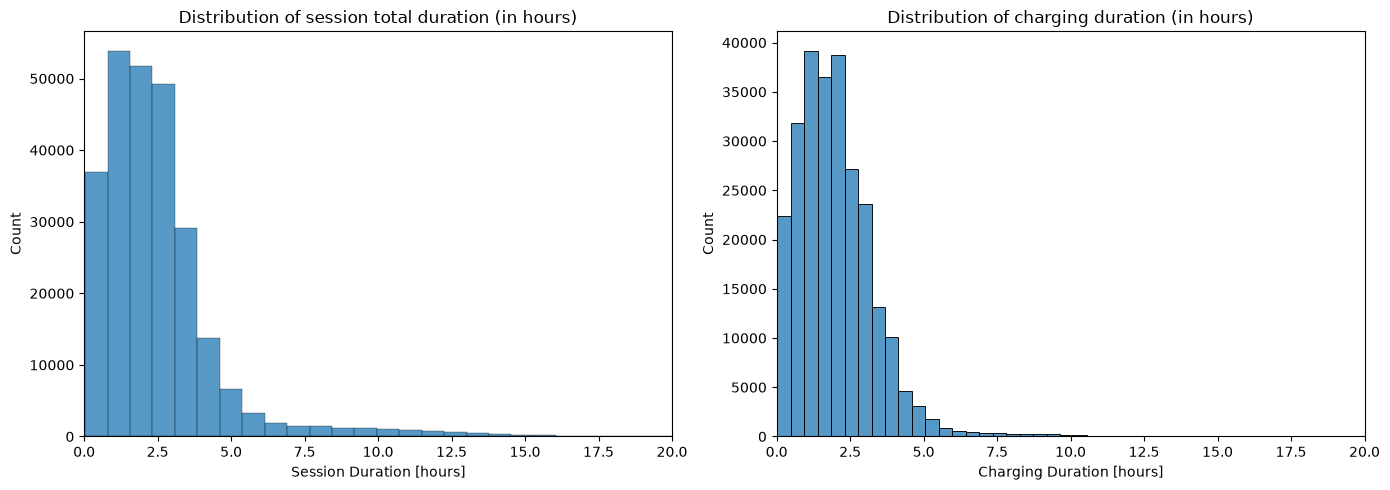

Charging time shorter by at least 15 min: 29.17%


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df, x="total_duration_hours",
    bins=150, ax=axes[0]
)
axes[0].set_title("Distribution of session total duration (in hours)")
axes[0].set_xlabel("Session Duration [hours]")

sns.histplot(
    data=df, x="charging_duration_hours",
    bins=50, ax=axes[1]
)
axes[1].set_title("Distribution of charging duration (in hours)")
axes[1].set_xlabel("Charging Duration [hours]")
axes[0].set_xlim(0, 20)
axes[1].set_xlim(0, 20)
plt.tight_layout()
plt.show()

valid = df[["charging_duration_hours", "total_duration_hours"]].dropna()
diff = valid["total_duration_hours"] - valid["charging_duration_hours"]
percent = (diff >= 15 / 60).mean() * 100

print(f"Charging time shorter by at least 15 min: {percent:.2f}%")

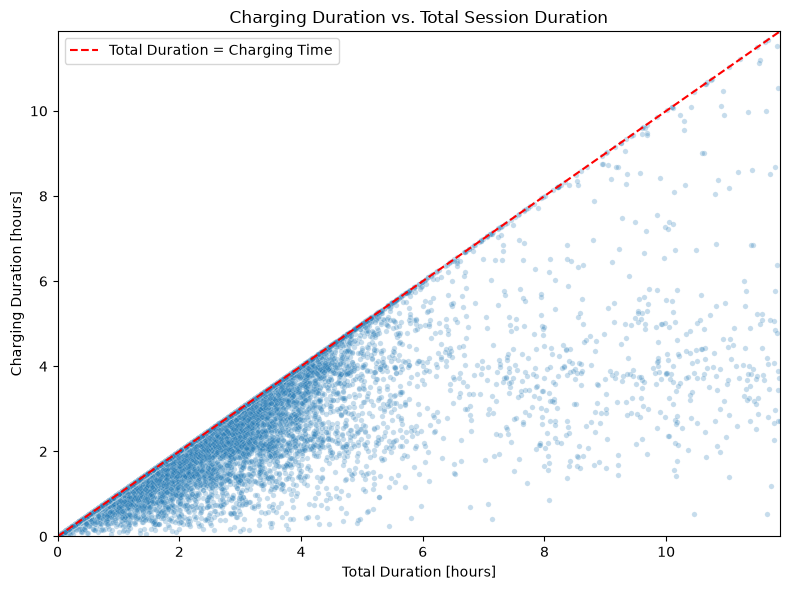

In [15]:
sample = df[
    ["total_duration_hours", "charging_duration_hours"]
].dropna()

if len(sample) > 20000:
    sample = sample.sample(20000, random_state=42)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=sample,
    x="total_duration_hours",
    y="charging_duration_hours",
    alpha=0.25,
    s=15
)

limit = sample[["total_duration_hours", "charging_duration_hours"]].quantile(0.99).max()
plt.plot([0, limit], [0, limit], "--", color="red",
         label="Total Duration = Charging Time")

plt.xlim(0, limit)
plt.ylim(0, limit)
plt.xlabel("Total Duration [hours]")
plt.ylabel("Charging Duration [hours]")
plt.title("Charging Duration vs. Total Session Duration")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
for col in ["total_duration_hours", "charging_duration_hours", "idle_hours"]:
    s = df[col]
    print(f"{col}: mean {s.mean():.2f} h | median {s.median():.2f} h | 90th percentile {s.quantile(0.9):.2f} h | max {s.max():.1f} h")

idle_min = df["idle_hours"] * 60
print(f"\nSessions with less than 1 min idle: {(idle_min < 1).mean():.0%}")
print(f"Sessions with more than 30 min idle: {(idle_min > 30).mean():.0%}")
top10 = df["idle_hours"].nlargest(int(len(df) * 0.1)).sum() / df["idle_hours"].sum()
print(f"Share of all idle hours from the 10% longest-idling sessions: {top10:.0%}")

total_duration_hours: mean 2.50 h | median 2.10 h | 90th percentile 4.34 h | max 114.5 h
charging_duration_hours: mean 2.01 h | median 1.83 h | 90th percentile 3.62 h | max 22.9 h
idle_hours: mean 0.49 h | median 0.01 h | 90th percentile 1.22 h | max 112.5 h

Sessions with less than 1 min idle: 59%
Sessions with more than 30 min idle: 20%
Share of all idle hours from the 10% longest-idling sessions: 73%


A typical session charges for about 1.8 h within a plug-in time of about 2.1 h (medians). The means (2.0 h and 2.5 h) are higher because a few sessions last very long; the longest is 114 h.

Idle time is very skewed. The mean is about 0.5 h, but the median is under a minute:
- 59% of sessions are unplugged within a minute of charging finishing.
- 20% stay plugged in for more than 30 minutes after charging.
- The 10% longest-idling sessions account for 73% of all idle hours.

So long idle times come from a minority of sessions, not from the typical session.

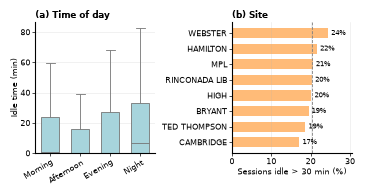

Overall share of sessions idle > 30 min: 20.4%


site
CAMBRIDGE        17.1
TED THOMPSON     18.6
BRYANT           19.5
HIGH             20.2
RINCONADA LIB    20.3
MPL              20.5
HAMILTON         21.6
WEBSTER          24.4
Name: mean, dtype: float64

In [56]:
MIN_SESSIONS = 500   # sites with fewer sessions are left out (too noisy)
TOD_ORDER = ["Morning", "Afternoon", "Evening", "Night"]

d = df.assign(idle_min=df["idle_hours"] * 60,
              idle_30=df["idle_hours"] > 0.5,
              site=df["Station Name"].str.replace(r"\s*\d+$", "", regex=True))
overall = 100 * d["idle_30"].mean()

# (b) share of sessions idle > 30 min by site
by_site = d.groupby("site")["idle_30"].agg(["mean", "size"])
by_site = (100 * by_site.loc[by_site["size"] >= MIN_SESSIONS, "mean"]).sort_values()

tiny_fonts = {"font.size": 6, "axes.titlesize": 6.5, "axes.titleweight": "bold",
              "axes.labelsize": 6, "xtick.labelsize": 5.5, "ytick.labelsize": 5.5,
              "legend.fontsize": 5.5, "axes.titlepad": 3}

with plt.rc_context(tiny_fonts):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(3.5, 1.8))

    # (a) idle time by time of day (outliers hidden)
    sns.boxplot(data=d, x="time_of_day", y="idle_min", order=TOD_ORDER, color="#9edae5",
                showfliers=False, width=0.6, linewidth=0.6, ax=ax1)
    ax1.set_xlabel("")
    ax1.tick_params(axis="x", rotation=30)
    plt.setp(ax1.get_xticklabels(), ha="right", rotation_mode="anchor")
    ax1.set_ylabel("Idle time (min)", labelpad=1)
    ax1.set_title("(a) Time of day", loc="left")
    ax1.set_ylim(bottom=0)
    ax1.grid(axis="y", alpha=0.3, lw=0.4)

    # (b) share of long-idle sessions by site
    ax2.barh(by_site.index, by_site.values, color="#ffbb78", height=0.65)
    ax2.axvline(overall, ls="--", c="grey", lw=0.6)
    for i, v in enumerate(by_site.values):
        ax2.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=5)
    ax2.set_xlim(0, by_site.max() * 1.25)
    ax2.set_xlabel("Sessions idle > 30 min (%)", labelpad=1)
    ax2.set_title("(b) Site", loc="left")
    ax2.grid(axis="x", alpha=0.3, lw=0.4)
    ax2.grid(axis="y", visible=False)

    for ax in (ax1, ax2):
        ax.tick_params(length=2, width=0.5, pad=1.5)
        sns.despine(ax=ax)

    fig.tight_layout(pad=0.3, w_pad=0.8)
    fig.savefig("figures/idle_patterns.pdf", bbox_inches="tight")
    plt.show()

print(f"Overall share of sessions idle > 30 min: {overall:.1f}%")
display(by_site.round(1))

## Stations analysis 

Street
Cambridge Ave     49171
Bryant St         46386
High St           39470
Hamilton Ave      38141
Webster St        37286
Middlefield Rd    28021
Newell Rd         18125
Sherman Ave          39


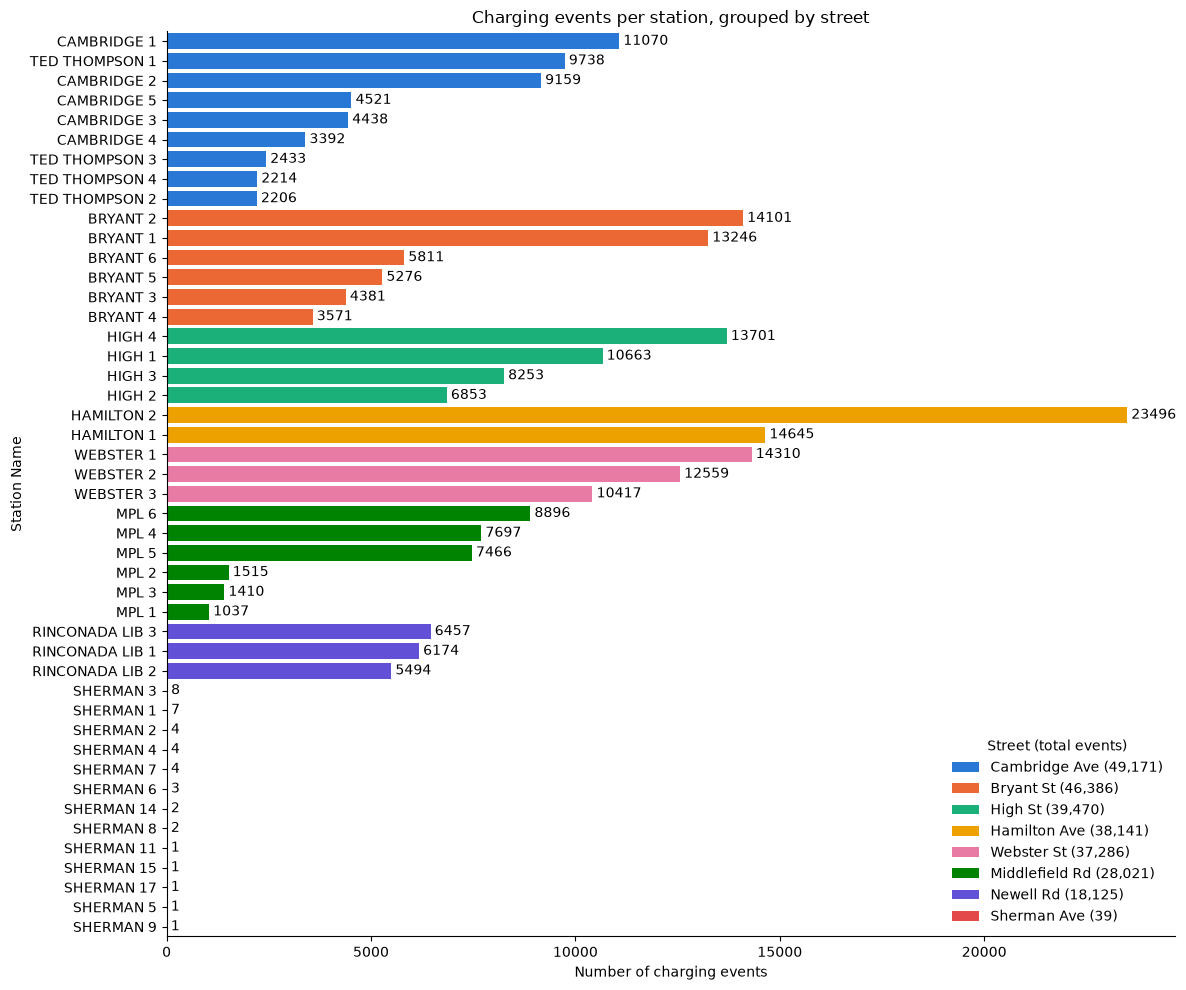

In [17]:
# charging events per station, grouped by street
# the street comes from the station name, which stays the same over time (Address 1 changes, see above)
STREET = {
    "BRYANT": "Bryant St",
    "CAMBRIDGE": "Cambridge Ave",
    "TED THOMPSON": "Cambridge Ave",
    "HAMILTON": "Hamilton Ave",
    "HIGH": "High St",
    "MPL": "Middlefield Rd",
    "RINCONADA LIB": "Newell Rd",
    "SHERMAN": "Sherman Ave",
    "WEBSTER": "Webster St",
}
# fixed colour per street (colour-blind-safe palette); streets listed busiest first,
# so neighbouring street blocks in the plot get neighbouring palette colours
STREET_COLORS = {
    "Cambridge Ave": "#2a78d6",
    "Bryant St": "#eb6834",
    "High St": "#1baf7a",
    "Hamilton Ave": "#eda100",
    "Webster St": "#e87ba4",
    "Middlefield Rd": "#008300",
    "Newell Rd": "#6250d6",
    "Sherman Ave": "#e34948",
}

station_counts = df.groupby("Station Name").size().rename("n_events").reset_index()
station_counts["Street"] = station_counts["Station Name"].str.replace(r"\s*\d+$", "", regex=True).map(STREET)
assert station_counts["Street"].notna().all(), "station without a street"

# street blocks in the order above, stations ranked within each street
station_counts["Street"] = pd.Categorical(station_counts["Street"], categories=list(STREET_COLORS), ordered=True)
station_counts = station_counts.sort_values(["Street", "n_events"], ascending=[True, False])
street_totals = station_counts.groupby("Street", observed=True)["n_events"].sum()
print(street_totals.to_string())

fig, ax = plt.subplots(figsize=(12, 10))
sns.barplot(data=station_counts, x="n_events", y="Station Name", hue="Street",
            order=station_counts["Station Name"], palette=STREET_COLORS, hue_order=list(STREET_COLORS),
            dodge=False, saturation=1, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Number of charging events")
ax.set_ylabel("Station Name")
ax.set_title("Charging events per station, grouped by street")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [f"{s} ({street_totals[s]:,})" for s in labels], title="Street (total events)", loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

In [18]:
top3 = (
    df.groupby(["year", "Station Name"])
      .size()
      .rename("n_events")
      .reset_index()
      .sort_values(["year", "n_events"], ascending=[True, False])
)
top3["rank"] = top3.groupby("year").cumcount() + 1
top3 = top3[top3["rank"] <= 3]
table = top3.pivot(index="year", columns="rank", values=["Station Name", "n_events"])
table.columns = [f"{'Station' if a == 'Station Name' else 'Events'} #{b}" for a, b in table.columns]
table = table[[f"{c} #{i}" for i in (1, 2, 3) for c in ("Station", "Events")]]   # parami: stacja, liczba

display(table)

,Station #1,Events #1,Station #2,Events #2,Station #3,Events #3
year,,,,,,
2011,HAMILTON 1,453,HAMILTON 2,394,HIGH 4,173
2012,HAMILTON 1,1390,HAMILTON 2,1367,BRYANT 2,1338
2013,BRYANT 2,2128,BRYANT 1,2081,HAMILTON 1,1945
2014,BRYANT 1,2463,BRYANT 2,2455,HIGH 4,2038
2015,BRYANT 2,2551,BRYANT 1,2387,HAMILTON 2,2050
2016,HAMILTON 2,3725,WEBSTER 1,3463,WEBSTER 2,3380
2017,HAMILTON 2,3488,WEBSTER 1,3174,CAMBRIDGE 1,2996
2018,HAMILTON 2,3406,WEBSTER 1,2633,WEBSTER 2,2148
2019,HAMILTON 2,3717,WEBSTER 1,2568,HIGH 3,2368


In [19]:
# sessions per active day: stations were installed between 2011 and December 2020, so total counts favour old stations
station_activity = (
    df.groupby("Station Name")["Start Date"]
    .agg(sessions="size", first="min", last="max")
    .assign(active_days=lambda x: (x["last"] - x["first"]).dt.days + 1)
    .assign(sessions_per_day=lambda x: (x["sessions"] / x["active_days"]).round(2))
)
station_activity["rank_total"] = station_activity["sessions"].rank(ascending=False, method="min").astype(int)
station_activity["rank_per_day"] = station_activity["sessions_per_day"].rank(ascending=False, method="min").astype(int)

display(station_activity.sort_values("sessions_per_day", ascending=False).head(15))
display(station_activity.sort_values("rank_total").head(10)[["sessions", "sessions_per_day", "rank_total", "rank_per_day"]])

,sessions,first,last,active_days,sessions_per_day,rank_total,rank_per_day
Station Name,,,,,,,
WEBSTER 1,14310,2015-07-29 13:59:00,2020-12-31 17:49:00,1983,7.22,3,1
HAMILTON 2,23496,2011-08-02 12:26:00,2020-11-04 04:54:00,3382,6.95,1,2
WEBSTER 2,12559,2015-07-29 16:53:00,2020-12-30 17:57:00,1982,6.34,7,3
CAMBRIDGE 1,11070,2016-01-14 11:19:00,2020-12-31 06:50:00,1813,6.11,8,4
WEBSTER 3,10417,2016-01-14 13:22:00,2020-12-31 14:19:00,1814,5.74,10,5
HIGH 3,8253,2017-01-06 18:40:00,2020-12-31 11:19:00,1455,5.67,14,6
TED THOMPSON 1,9738,2016-01-14 10:28:00,2020-10-11 10:06:00,1732,5.62,11,7
HIGH 1,10663,2015-07-29 15:51:00,2020-12-31 09:37:00,1982,5.38,9,8
CAMBRIDGE 2,9159,2016-01-14 13:45:00,2020-12-29 09:06:00,1811,5.06,12,9


,sessions,sessions_per_day,rank_total,rank_per_day
Station Name,,,,
HAMILTON 2,23496,6.95,1,2
HAMILTON 1,14645,4.33,2,15
WEBSTER 1,14310,7.22,3,1
BRYANT 2,14101,4.42,4,13
HIGH 4,13701,4.05,5,17
BRYANT 1,13246,3.94,6,18
WEBSTER 2,12559,6.34,7,3
CAMBRIDGE 1,11070,6.11,8,4
HIGH 1,10663,5.38,9,8


In [49]:
PAIRS = ["HAMILTON 1", "HAMILTON 2", "WEBSTER 1", "WEBSTER 2"]
d = df[df["Station Name"].isin(PAIRS)].copy()
d["power_kw"] = d["Energy (kWh)"] / d["charging_duration_hours"]

active_days = d.groupby("Station Name")["Start Date"].agg(lambda s: (s.max() - s.min()).days + 1)

compare = d.groupby("Station Name").agg(
    sessions=("Start Date", "size"),
    ports=("Port Number", "nunique"),
    level1_share=("Port Type", lambda s: (s == "Level 1").mean() * 100),
    median_power_kw=("power_kw", "median"),
    median_energy_kwh=("Energy (kWh)", "median"),
    median_total_h=("total_duration_hours", "median"),
    idle_over_30min=("idle_hours", lambda s: (s > 0.5).mean() * 100),
)
compare["sessions_per_day"] = compare["sessions"] / active_days
compare["sessions_per_port_per_day"] = compare["sessions_per_day"] / compare["ports"]
display(compare.round(2))

# charger models over time (hardware can be replaced, see MAC analysis)
display(d.groupby(["Station Name", "Model Number"], dropna=False)["Start Date"]
          .agg(sessions="size", first="min", last="max"))

# port types per port number
display(pd.crosstab([d["Station Name"], d["Port Number"]], d["Port Type"]))

,sessions,ports,level1_share,median_power_kw,median_energy_kwh,median_total_h,idle_over_30min,sessions_per_day,sessions_per_port_per_day
Station Name,,,,,,,,,
HAMILTON 1,14645,2,3.32,3.40,6.45,2.20,22.62,4.33,2.16
HAMILTON 2,23496,2,1.03,3.46,6.66,2.15,20.96,6.95,3.47
WEBSTER 1,14310,2,0.00,4.33,7.88,2.39,23.52,7.22,3.61
WEBSTER 2,12559,2,0.00,4.81,8.14,2.43,25.90,6.34,3.17


sessions               first  \
Station Name Model Number                                       
HAMILTON 1   CT2100-HD-CDMA-CCR     14645 2011-07-29 20:17:00   
HAMILTON 2   CT2100-HD-CCR           7698 2011-08-02 12:26:00   
             CT4020-HD-GW           15798 2016-01-12 18:44:00   
WEBSTER 1    CT4020-HD-GW           14310 2015-07-29 13:59:00   
WEBSTER 2    CT4020-HD              10701 2015-07-29 16:53:00   
             CT4020-HD-GW            1858 2019-07-01 07:53:00   

                                               last  
Station Name Model Number                            
HAMILTON 1   CT2100-HD-CDMA-CCR 2020-11-03 13:59:00  
HAMILTON 2   CT2100-HD-CCR      2016-01-12 11:17:00  
             CT4020-HD-GW       2020-11-04 04:54:00  
WEBSTER 1    CT4020-HD-GW       2020-12-31 17:49:00  
WEBSTER 2    CT4020-HD          2019-06-30 17:37:00  
             CT4020-HD-GW       2020-12-30 17:57:00

Port Type                 Level 1  Level 2  missing
Station Name Port Number                           
HAMILTON 1   1                486        0        0
             2                  0    14159        0
HAMILTON 2   1                243     7844        0
             2                  0    15408        1
WEBSTER 1    1                  0     6517        0
             2                  0     7793        0
WEBSTER 2    1                  0     5889        0
             2                  0     6670        0

By street, Cambridge Ave has the most sessions (about 49,500 from 9 stations, including the TED THOMPSON stations), followed by Bryant St (46,900) and High St (39,800). Hamilton Ave has only 2 stations but almost as many sessions (38,500), because HAMILTON 2 is the busiest single station.

By total sessions, HAMILTON 2 leads, followed by HAMILTON 1, WEBSTER 1 and BRYANT 2. The leaders change over time: HAMILTON and BRYANT stations lead until 2015, HAMILTON 2 and the WEBSTER stations from 2016.

Total counts favour stations that have been running longest, and stations were added between 2011 and 2020. Sessions per active day is a fairer comparison:
- WEBSTER 1 (7.3 sessions per day) and HAMILTON 2 (7.0) are the busiest.
- HAMILTON 1 drops from #2 by total to #15 per day, and BRYANT 1 from #6 to #18. Their high totals come from running since 2011.
- The SHERMAN stations have few sessions because they were installed in December 2020, at the very end of the data, not because they are unused.

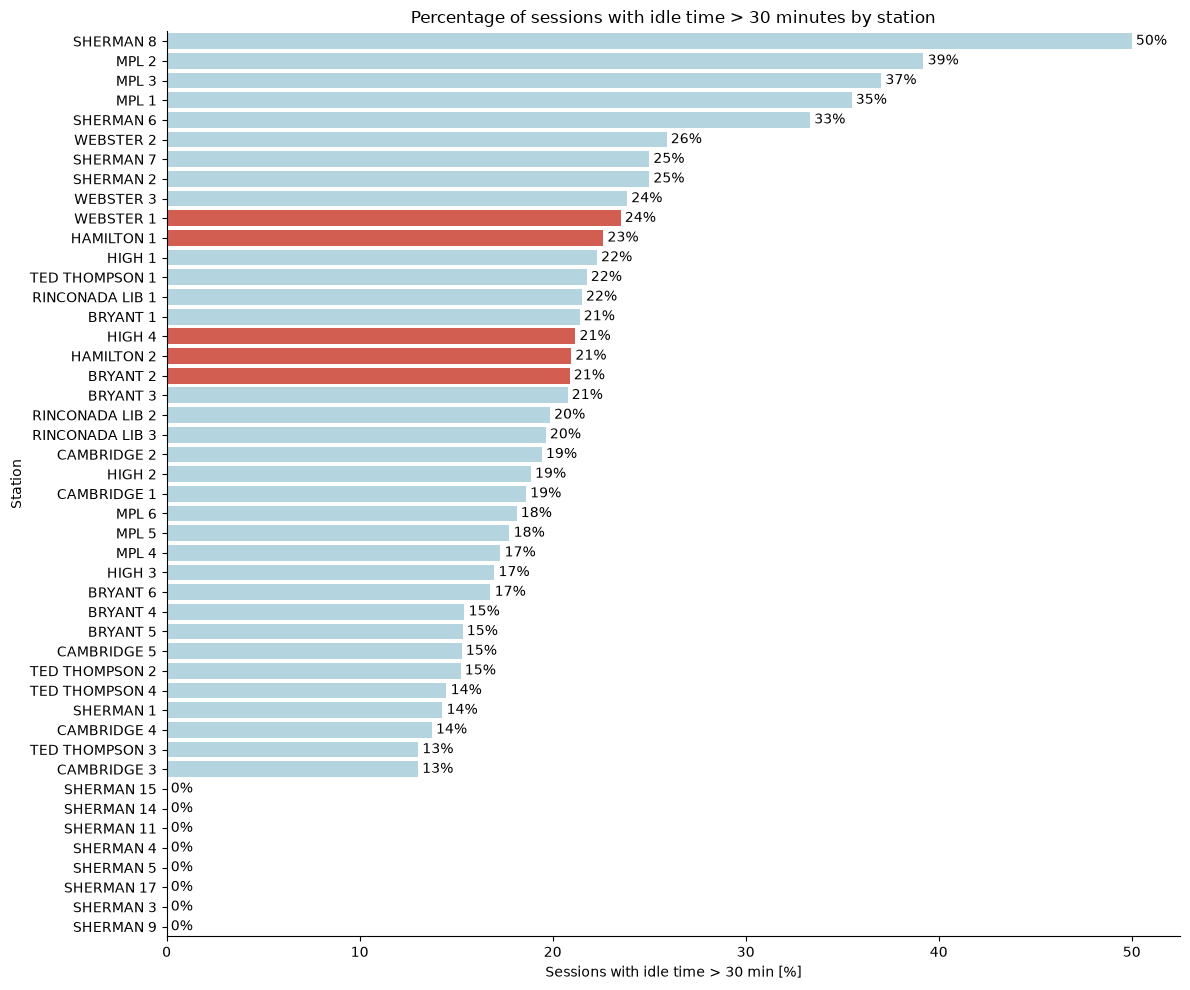

In [20]:
# plot the percentage of sessions with idle time greater than 30 minutes for each station
# the 5 stations with the most sessions are highlighted in red
idle_pct = (
    df.groupby("Station Name")["idle_hours"]
    .agg(
        total="count",
        above_30min=lambda x: (x > 30 / 60).sum()
    )
    .assign(percent=lambda x: 100 * x["above_30min"] / x["total"])
    .sort_values("percent", ascending=False)
)

highlight_stations = df["Station Name"].value_counts().head(5).index

plot_data = idle_pct.reset_index()
plot_data["color"] = plot_data["Station Name"].apply(
    lambda x: "Highlight" if x in highlight_stations else "Other"
)

palette = {"Highlight": "#e74c3c", "Other": "lightblue"}

fig, ax = plt.subplots(figsize=(12, 10))

sns.barplot(
    data=plot_data,
    x="percent",
    y="Station Name",
    hue="color",
    palette=palette,
    dodge=False,
    legend=False,
    ax=ax
)
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", padding=3)

ax.set_xlabel("Sessions with idle time > 30 min [%]")
ax.set_ylabel("Station")
ax.set_title("Percentage of sessions with idle time > 30 minutes by station")

sns.despine()
plt.tight_layout()
plt.show()

In [21]:
# number of sessions behind each percentage, and the overall average
print(f"Sessions idle > 30 min, all stations: {100 * (df['idle_hours'] > 0.5).mean():.1f}%")
display(idle_pct[["total", "percent"]].round(1).head(12))

Sessions idle > 30 min, all stations: 20.4%


,total,percent
Station Name,,
SHERMAN 8,2,50.0
MPL 2,1515,39.2
MPL 3,1410,37.0
MPL 1,1037,35.5
SHERMAN 6,3,33.3
WEBSTER 2,12559,25.9
SHERMAN 7,4,25.0
SHERMAN 2,4,25.0
WEBSTER 3,10417,23.9


On average, about 20% of sessions stay idle for more than 30 minutes.
- The SHERMAN stations at the top have only 1–8 sessions each, so their percentages are not meaningful.
- MPL 1, 2 and 3 are genuinely high (35–39%), with 1,000–1,500 sessions each. These chargers at Mitchell Park Library are often left plugged in after charging.
- The 5 most-used stations are at 21–23%, close to the average. WEBSTER 2 (26%) is the highest of the busy stations.

## Port type analysis

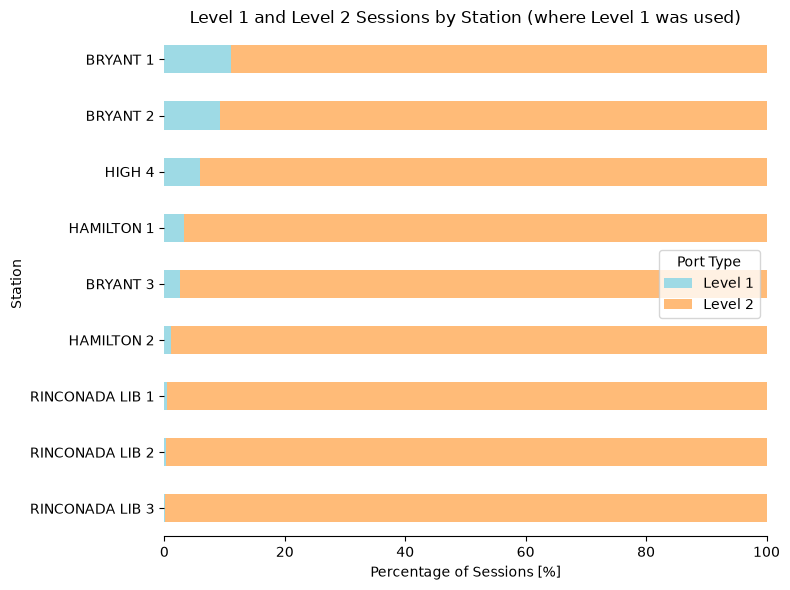

In [22]:
# Stations where at least one Level 1 session occurred
stations_level1 = df.loc[
    df["Port Type"] == "Level 1", "Station Name"
].unique()

df_levels = df[
    df["Station Name"].isin(stations_level1)
    & df["Port Type"].isin(["Level 1", "Level 2"])
].copy()

level_pct = pd.crosstab(
    df_levels["Station Name"],
    df_levels["Port Type"],
    normalize="index"
) * 100

level_pct = level_pct.reindex(
    columns=["Level 1", "Level 2"], fill_value=0
).sort_values("Level 2", ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))

level_pct.plot(
    kind="barh",
    stacked=True,
    color=["#9edae5", "#ffbb78"],
    ax=ax
)


ax.set_xlabel("Percentage of Sessions [%]")
ax.set_ylabel("Station")
ax.set_title("Level 1 and Level 2 Sessions by Station (where Level 1 was used)")
ax.legend(title="Port Type")
ax.set_xlim(0, 100)


sns.despine(ax=ax)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

Port Type = Level 1 was only used at 9 stations, and the % of events with Level1 are less than 20% on each station.

## Durations deeper-dive

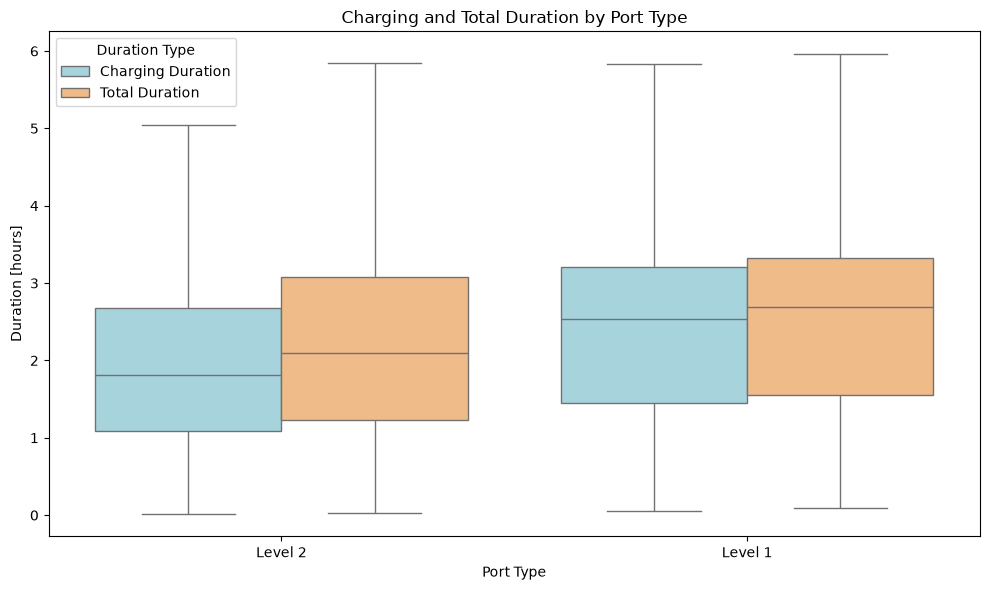

In [23]:
# plot the distribution of charging/total duration for Level 1 and Level 2 sessions
df_plot = df_levels.melt(
    id_vars="Port Type",
    value_vars=["charging_duration_hours", "total_duration_hours"],
    var_name="Duration Type",
    value_name="Duration [hours]"
)

df_plot["Duration Type"] = df_plot["Duration Type"].map({
    "charging_duration_hours": "Charging Duration",
    "total_duration_hours": "Total Duration"
})

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_plot,
    x="Port Type",
    y="Duration [hours]",
    hue="Duration Type",
    showfliers=False,
    palette=["#9edae5", "#ffbb78"]
)

plt.xlabel("Port Type")
plt.ylabel("Duration [hours]")
plt.title("Charging and Total Duration by Port Type")
plt.legend(title="Duration Type")
plt.tight_layout()
plt.show()

In [24]:
# medians by port type, plus the median charging power (energy / charging time)
port_summary = df.groupby("Port Type").agg(
    sessions=("Energy (kWh)", "size"),
    charging_h=("charging_duration_hours", "median"),
    total_h=("total_duration_hours", "median"),
    energy_kwh=("Energy (kWh)", "median"),
)
port_summary["power_kw"] = (df["Energy (kWh)"] / df["charging_duration_hours"]).groupby(df["Port Type"]).median()
port_summary["share_of_sessions_%"] = 100 * port_summary["sessions"] / port_summary["sessions"].sum()

display(port_summary.round(2))

,sessions,charging_h,total_h,energy_kwh,power_kw,share_of_sessions_%
Port Type,,,,,,
Level 1,4477,2.53,2.68,2.82,1.28,1.74
Level 2,252161,1.82,2.10,6.99,3.74,98.26
missing,1,1.73,1.73,5.14,2.98,0.00


Level 1 is clearly slower. A Level 1 session charges for longer (median 2.5 h vs 1.8 h) but delivers much less energy (2.8 kWh vs 7.0 kWh), at about 1.3 kW instead of 3.7 kW.

The gap between total and charging time is larger for Level 2 (medians 2.08 − 1.81 = 0.27 h vs 2.63 − 2.47 = 0.16 h for Level 1).

Level 1 is only about 2% of all sessions, so it has little effect on the overall results.

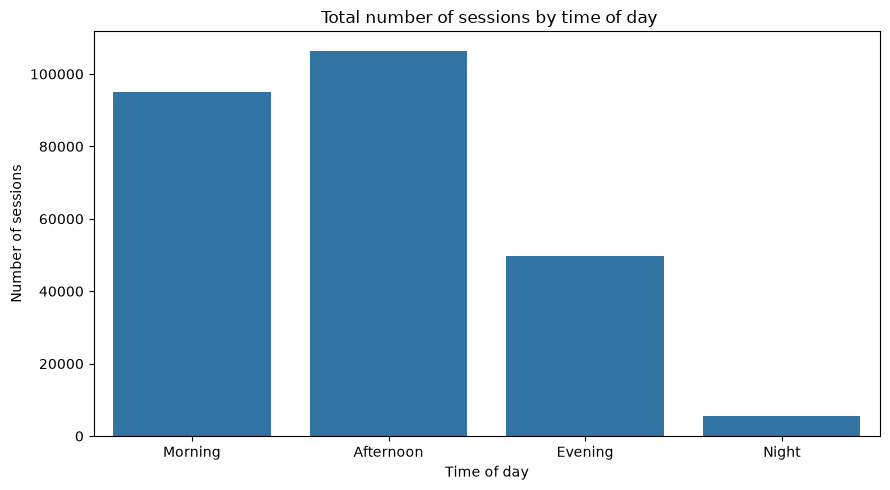

In [25]:
# plot the number of sessions by time of day
order = [ "Morning", "Afternoon", "Evening", "Night"]

plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="time_of_day",
    order=order,
    legend=False
)

plt.xlabel("Time of day")
plt.ylabel("Number of sessions")
plt.title(" Total number of sessions by time of day")
plt.tight_layout()
plt.show()

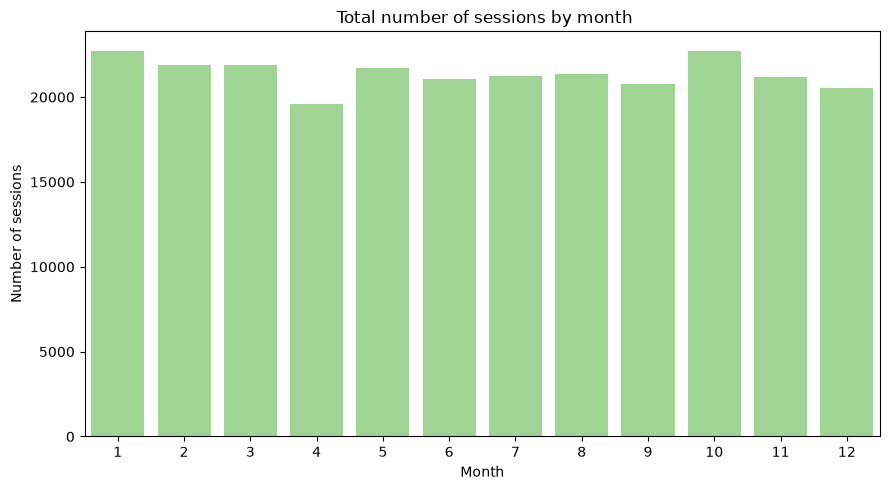

In [26]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="month",
    color="#98df8a",
    legend=False
)

plt.xlabel("Month")
plt.ylabel("Number of sessions")
plt.title(" Total number of sessions by month")
plt.tight_layout()
plt.show()

In [27]:
# the plot above adds up all years, including the partial 2011 (from July) and 2020 (COVID)
# for seasonality, use full years only: each month's share of that year's sessions
full_years = df[df["year"].between(2016, 2019)]
monthly = full_years.groupby(["year", "month"]).size()
month_share = 100 * monthly / monthly.groupby(level="year").transform("sum")

display(month_share.groupby(level="month").mean().round(1).rename("avg % of the year's sessions (2016-2019)"))

month
1     8.1
2     7.8
3     8.7
4     8.3
5     9.1
6     8.7
7     8.7
8     8.4
9     7.9
10    8.6
11    7.9
12    7.7
Name: avg % of the year's sessions (2016-2019), dtype: float64

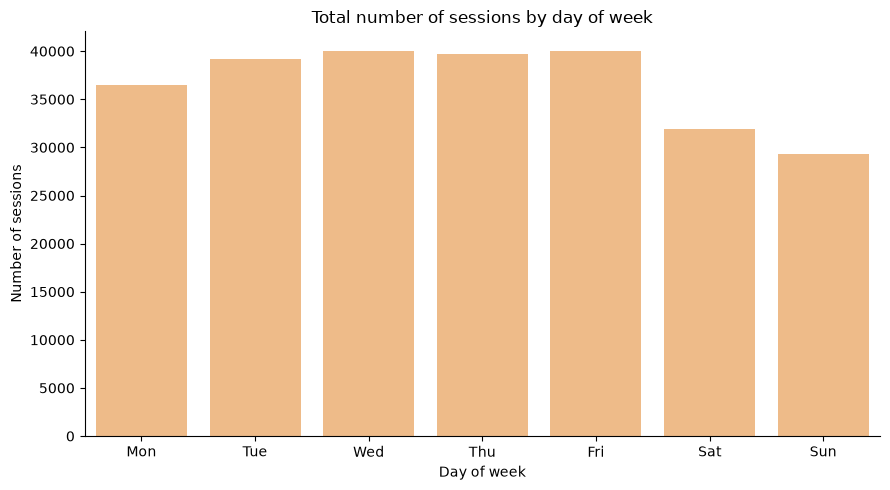

In [28]:
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.figure(figsize=(9, 5))
ax = sns.countplot(
    data=df,
    x="day_of_week",
    order=range(7),         
    color="#ffbb78"
)

ax.set_xticks(range(7))
ax.set_xticklabels(day_names)
ax.spines[["top", "right"]].set_visible(False)

plt.xlabel("Day of week")
plt.ylabel("Number of sessions")
plt.title("Total number of sessions by day of week")
plt.tight_layout()
plt.show()

Most sessions start in the morning and afternoon, and on weekdays: about 40,000 each from Tuesday to Friday, compared with about 30,000 on Sunday.

There is no clear seasonality by month. The monthly plot adds up all years, including the partial 2011 (data from July) and 2020 (COVID). Over the full years 2016–2019, each month has between 7.7% and 9.1% of the year's sessions.

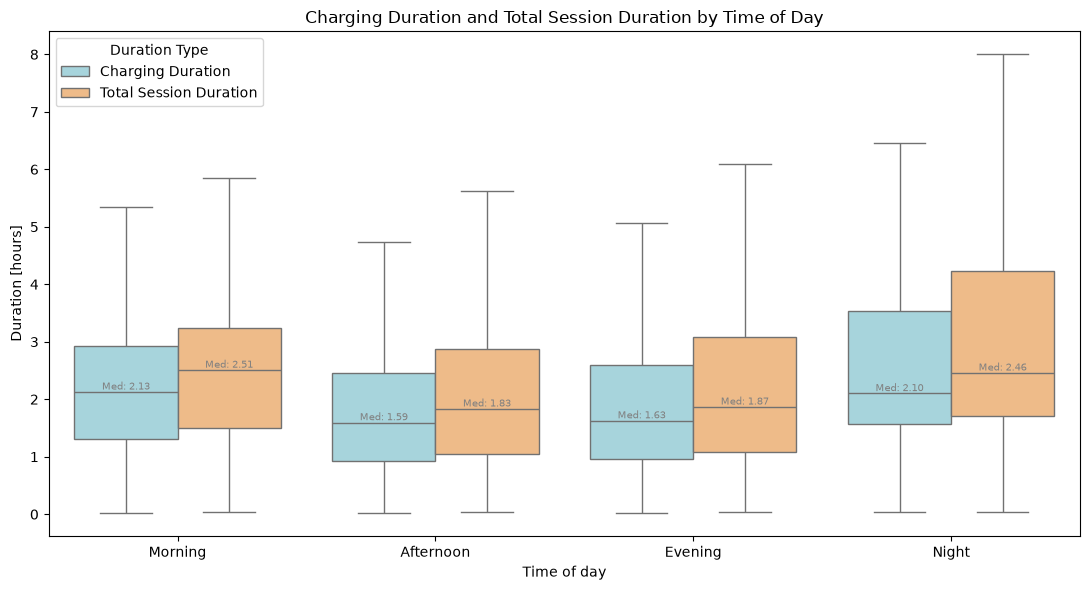

In [29]:
# plot the distribution of charging / total duration for each time of day
df_plot = df.melt(
    id_vars="time_of_day",
    value_vars=["charging_duration_hours", "total_duration_hours"],
    var_name="Duration Type",
    value_name="Duration [hours]"
)

df_plot["Duration Type"] = df_plot["Duration Type"].map({
    "charging_duration_hours": "Charging Duration",
    "total_duration_hours": "Total Session Duration"
})

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df_plot,
    x="time_of_day",
    y="Duration [hours]",
    order=order,
    hue="Duration Type",
    palette=["#9edae5", "#ffbb78"],
    showfliers=False
)

plt.xlabel("Time of day")
plt.ylabel("Duration [hours]")
plt.title("Charging Duration and Total Session Duration by Time of Day")
plt.legend(title="Duration Type")
# add median labels
medians = df_plot.groupby(["time_of_day", "Duration Type"])["Duration [hours]"].median()
offsets = [-0.2, 0.2]
ax = plt.gca()

for i, tod in enumerate(order):
    for j, duration_type in enumerate(["Charging Duration", "Total Session Duration"]):
        if (tod, duration_type) not in medians.index:
            continue
        median = medians[(tod, duration_type)]
        ax.text(i + offsets[j], median, f"Med: {median:.2f}",
                ha="center", va="bottom", fontsize=7, color="gray")
plt.tight_layout()
plt.show()

Sessions started in the morning and at night charge and stay plugged in the longest: medians of 2.1 h charging and about 2.5 h in total for both. The biggest gap between the median charging and total time is 0.38 h, in the morning.

Night has the widest spread: its upper whisker reaches about 8 h of total duration (outliers are not shown in the plot). Night sessions are only about 2% of all sessions, so these values rest on far fewer sessions.

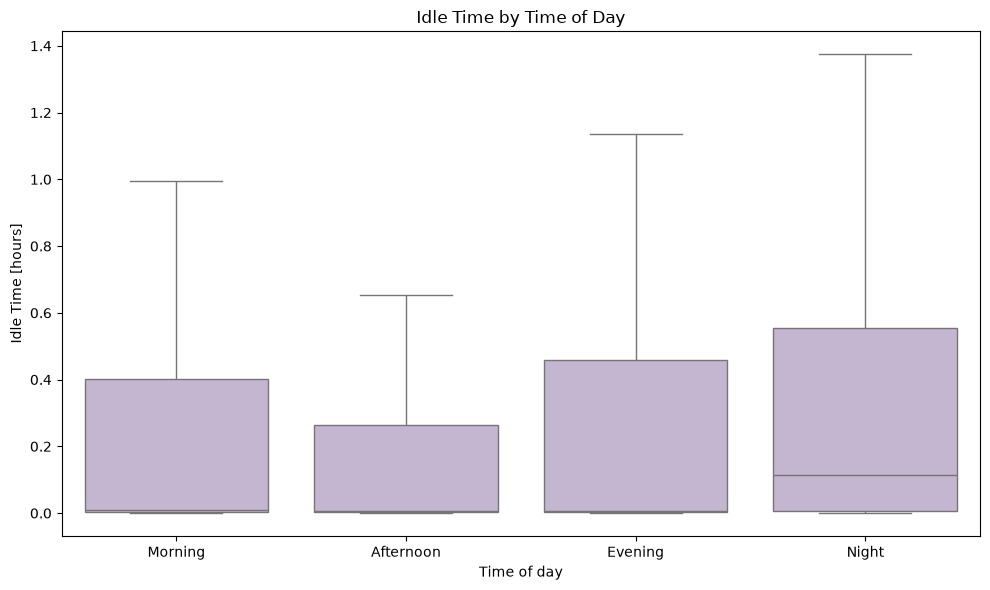

In [30]:
# Idle time analysis by time of day
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df[df["idle_hours"] >= 0],
    x="time_of_day",
    y="idle_hours",
    order=order,
    color="#c5b0d5",
    showfliers=False,
    legend=False
)

plt.xlabel("Time of day")
plt.ylabel("Idle Time [hours]")
plt.title("Idle Time by Time of Day")
plt.tight_layout()
plt.show()

Sessions started at night have the most idle time: a median of about 0.1 h (6 minutes), compared with under a minute at other times of day. Their upper whisker reaches about 1.4 h.

## Time Analysis

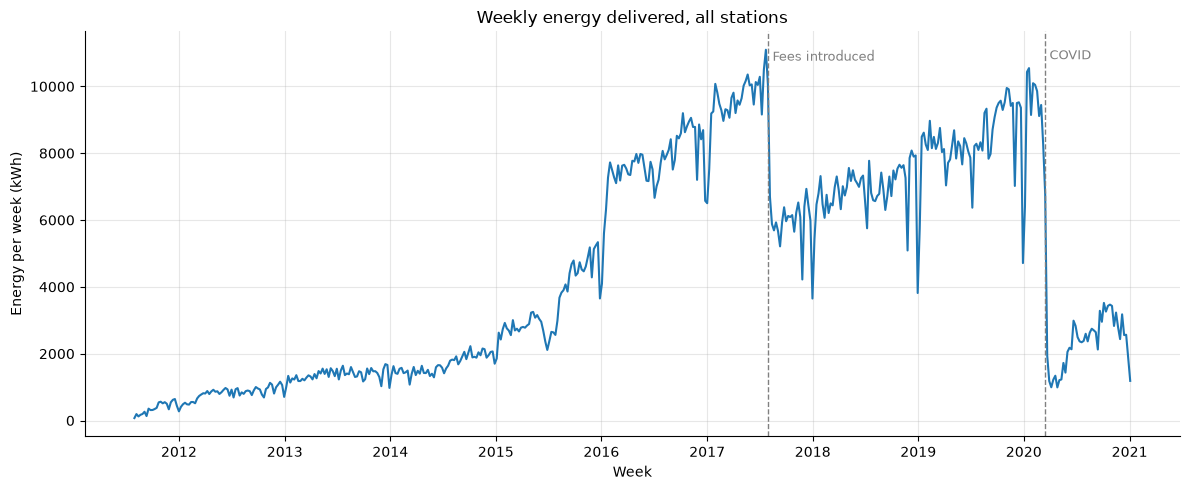

In [31]:
# weekly totals: one point per session is too dense to read
weekly_energy = df.set_index("Start Date")["Energy (kWh)"].sort_index().resample("W").sum()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(weekly_energy.index, weekly_energy.values, linewidth=1.5)

# mark the two events explained below
for date, label in [("2017-08-01", "Fees introduced"), ("2020-03-16", "COVID")]:
    ax.axvline(pd.Timestamp(date), color="gray", linestyle="--", linewidth=1)
    ax.text(pd.Timestamp(date), weekly_energy.max(), f" {label}", color="gray", fontsize=9, va="top")

ax.set_xlabel("Week")
ax.set_ylabel("Energy per week (kWh)")
ax.set_title("Weekly energy delivered, all stations")
ax.grid(True, alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

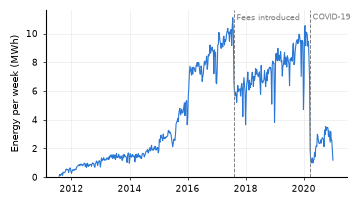

In [57]:
# for a report :

weekly_energy = df.set_index("Start Date")["Energy (kWh)"].sort_index().resample("W").sum()

small_fonts = {"font.size": 7, "axes.labelsize": 7, "xtick.labelsize": 6.5,
               "ytick.labelsize": 6.5}

with plt.rc_context(small_fonts):
    fig, ax = plt.subplots(figsize=(3.5, 1.9))
    ax.plot(weekly_energy.index, weekly_energy.values / 1000, color="#2a78d6", lw=0.8)

    # mark the two events
    for date, label in [("2017-08-01", "Fees introduced"), ("2020-03-16", "COVID-19")]:
        ax.axvline(pd.Timestamp(date), color="gray", ls="--", lw=0.7)
        ax.text(pd.Timestamp(date), 0.98, f" {label}", transform=ax.get_xaxis_transform(),
                color="gray", fontsize=6, va="top", ha="left")

    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_ylim(bottom=0)
    ax.set_ylabel("Energy per week (MWh)")
    ax.grid(True, alpha=0.3, lw=0.4)
    ax.tick_params(length=2, width=0.5)
    sns.despine(ax=ax)

    fig.tight_layout(pad=0.3)
    fig.savefig("figures/weekly_energy.pdf", bbox_inches="tight")
    plt.show()

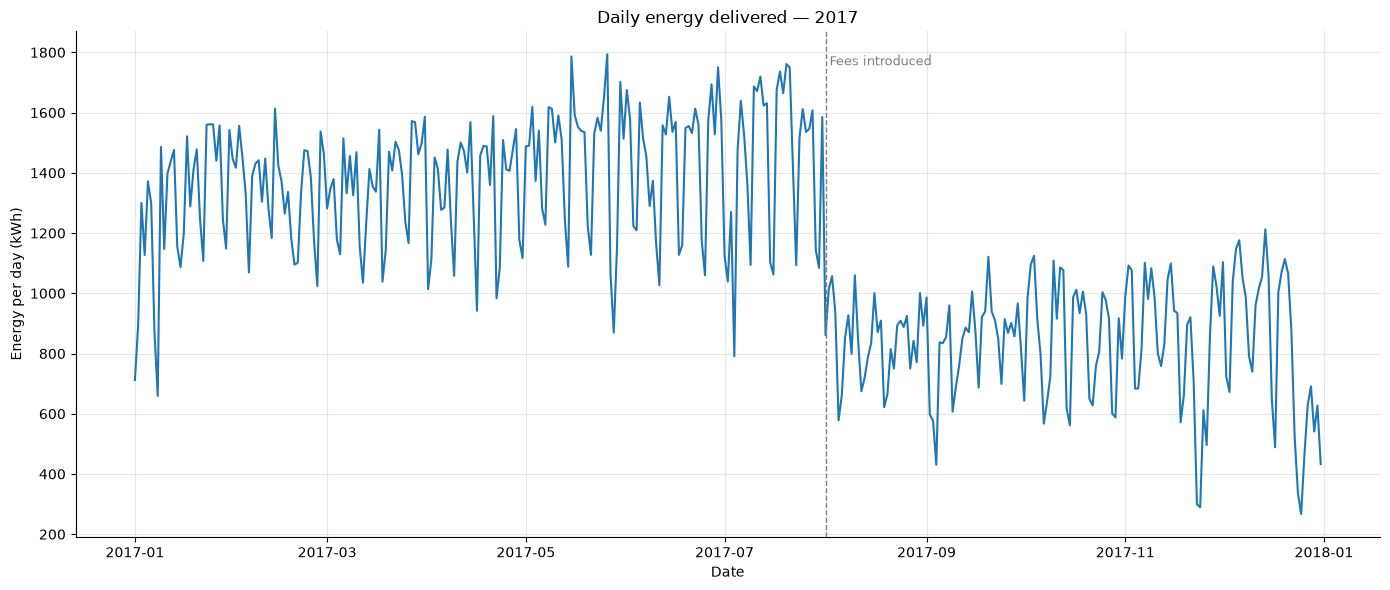

In [32]:
# zoom in on one year: daily totals
year = 2017
daily_energy = (
    df.loc[df["Start Date"].dt.year == year]
    .set_index("Start Date")["Energy (kWh)"]
    .sort_index()
    .resample("D").sum()
)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(daily_energy.index, daily_energy.values, linewidth=1.5)
ax.axvline(pd.Timestamp(f"{year}-08-01"), color="gray", linestyle="--", linewidth=1)
ax.text(pd.Timestamp(f"{year}-08-01"), daily_energy.max(), " Fees introduced", color="gray", fontsize=9, va="top")

ax.set_xlabel("Date")
ax.set_ylabel("Energy per day (kWh)")
ax.set_title(f"Daily energy delivered — {year}")
ax.grid(True, alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

In [33]:
# yearly totals: total energy grows mostly with the number of stations, not with energy per session
display(
    df.groupby("year").agg(
        sessions=("Energy (kWh)", "size"),
        stations=("Station Name", "nunique"),
        total_kwh=("Energy (kWh)", "sum"),
        mean_kwh=("Energy (kWh)", "mean"),
        median_kwh=("Energy (kWh)", "median"),
    ).round(1)
)

# monthly sessions around the two drops
monthly_sessions = df.groupby(df["Start Date"].dt.to_period("M")).size()
display(monthly_sessions.loc["2017-05":"2017-10"].rename("sessions"))
display(monthly_sessions.loc["2020-01":"2020-08"].rename("sessions"))

,sessions,stations,total_kwh,mean_kwh,median_kwh
year,,,,,
2011,1262,5,8340.6,6.6,6.1
2012,6521,5,42842.9,6.6,5.8
2013,9871,5,71419.4,7.2,6.1
2014,11477,11,87617.0,7.6,6.3
2015,22828,17,180574.0,7.9,6.7
2016,46512,22,404579.8,8.7,7.3
2017,48510,27,420461.8,8.7,7.2
2018,42405,33,359448.0,8.5,6.8
2019,47322,33,437093.3,9.2,7.0


Start Date
2017-05    4950
2017-06    4717
2017-07    4898
2017-08    3421
2017-09    3224
2017-10    3308
Freq: M, Name: sessions, dtype: int64

Start Date
2020-01    4402
2020-02    4059
2020-03    1986
2020-04     485
2020-05     685
2020-06    1093
2020-07    1159
2020-08    1173
Freq: M, Name: sessions, dtype: int64

Total energy grew mostly because the network grew, from 5 stations in 2011–2013 to 33 in 2018–2019 and 46 in 2020. Energy per session barely changed: the median stays around 6–7 kWh. The mean rises from 6.6 to 9.8 kWh because there are more very long sessions.

There are two clear drops:
- **August 2017:** sessions fell by about 30%, from about 4,900 in July to 3,500 in August. This is when charging fees were introduced: `Fee` is 0 until July 2017 and above 0 for 99% of sessions from 2018.
- **March–April 2020:** sessions fell from about 4,000 per month to under 500 in April (COVID) and stayed around 1,000–1,500 for the rest of 2020.

## Further analyses

Six topics the EDA above does not cover yet: the effect of the charging fee, energy per session, users, when sessions start, how busy the stations are, and outliers.

In [34]:
from matplotlib.colors import LinearSegmentedColormap

# single-hue sequential colour scale (light to dark blue) for counts
sequential_blue = LinearSegmentedColormap.from_list("sequential_blue", [
    "#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
    "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b",
])

### Charging fee (from August 2017)

In [35]:
# how the fee is calculated: fee per kWh, per plug-in hour and per charging hour (paid sessions only)
paid = df[df["Fee"] > 0]
print("First paid session:", paid["Start Date"].min())
print(f"Paid sessions from 2018: {(df.loc[df['year'] >= 2018, 'Fee'] > 0).mean():.1%}")

fee_rates = pd.DataFrame({
    "per kWh": paid["Fee"] / paid["Energy (kWh)"],
    "per plug-in hour": paid["Fee"] / paid["total_duration_hours"],
    "per charging hour": paid["Fee"] / paid["charging_duration_hours"],
})
display(fee_rates.describe(percentiles=[0.1, 0.5, 0.9]).round(3))
print("Median fee per kWh by year:", (paid["Fee"] / paid["Energy (kWh)"]).groupby(paid["year"]).median().round(3).to_dict())

First paid session: 2017-08-01 05:16:00
Paid sessions from 2018: 99.8%


,per kWh,per plug-in hour,per charging hour
count,125414.000,125414.000,125414.000
mean,0.271,1.000,1.177
std,0.413,0.344,1.258
min,0.001,0.003,0.003
10%,0.229,0.586,0.684
50%,0.230,1.021,1.242
90%,0.237,1.387,1.405
max,68.415,8.734,171.286


Median fee per kWh by year: {2017: 0.23, 2018: 0.23, 2019: 0.23, 2020: 0.23}


In [36]:
# 12 months before vs 12 months after fees started, on the stations that were running throughout both periods
fee_start = pd.Timestamp("2017-08-01")
station_span = df.groupby("Station Name")["Start Date"].agg(["min", "max"])
stations_both = station_span[(station_span["min"] < "2016-09-01") & (station_span["max"] >= "2018-07-01")].index
print("Stations running in both periods:", len(stations_both))

fee_window = df[
    df["Station Name"].isin(stations_both)
    & (df["Start Date"] >= fee_start - pd.DateOffset(years=1))
    & (df["Start Date"] < fee_start + pd.DateOffset(years=1))
].assign(period=lambda x: np.where(x["Start Date"] < fee_start, "before fees", "after fees"))

known_user = fee_window["User ID"].notna() & ~fee_window["User ID"].isin(["missing", "0"])
fee_summary = fee_window.groupby("period").agg(
    sessions_per_day=("Energy (kWh)", lambda s: len(s) / 365),
    total_h_median=("total_duration_hours", "median"),
    charging_h_median=("charging_duration_hours", "median"),
    energy_kwh_median=("Energy (kWh)", "median"),
    share_over_4h=("total_duration_hours", lambda s: (s > 4).mean()),
    share_idle_over_30min=("idle_hours", lambda s: (s > 0.5).mean()),
    share_idle_over_2h=("idle_hours", lambda s: (s > 2).mean()),
)
fee_summary["users"] = fee_window[known_user].groupby("period")["User ID"].nunique()
display(fee_summary.loc[["before fees", "after fees"]].T.round(3))

change = fee_summary.loc["after fees"] / fee_summary.loc["before fees"] - 1
print("Relative change after fees:", {k: f"{v:+.0%}" for k, v in change.items()})

users_before = set(fee_window.loc[known_user & (fee_window["period"] == "before fees"), "User ID"])
users_after = set(fee_window.loc[known_user & (fee_window["period"] == "after fees"), "User ID"])
stayed = users_before & users_after
print(f"Users before: {len(users_before):,} | after: {len(users_after):,} | in both periods: {len(stayed):,}")
stayed_sessions = fee_window[fee_window["User ID"].isin(stayed)].groupby("period").size()
print("Sessions of users present in both periods:", stayed_sessions.loc[["before fees", "after fees"]].to_dict(),
      f"({stayed_sessions['after fees'] / stayed_sessions['before fees'] - 1:+.0%})")

# stations that opened around the fee start can take sessions away from the stations compared above
opened = station_span[(station_span["min"] >= "2017-01-01") & (station_span["min"] < "2018-08-01")]["min"]
print("Stations opened between January 2017 and July 2018:", opened.dt.strftime("%Y-%m-%d").sort_values().to_dict())

Stations running in both periods: 22


period,before fees,after fees
sessions_per_day,134.184,81.748
total_h_median,2.345,1.959
charging_h_median,1.971,1.727
energy_kwh_median,7.460,6.646
share_over_4h,0.165,0.088
share_idle_over_30min,0.263,0.172
share_idle_over_2h,0.094,0.035
users,5008.000,5683.000


Relative change after fees: {'sessions_per_day': '-39%', 'total_h_median': '-16%', 'charging_h_median': '-12%', 'energy_kwh_median': '-11%', 'share_over_4h': '-47%', 'share_idle_over_30min': '-35%', 'share_idle_over_2h': '-63%', 'users': '+13%'}
Users before: 5,008 | after: 5,683 | in both periods: 2,136
Sessions of users present in both periods: {'before fees': 31440, 'after fees': 18449} (-41%)
Stations opened between January 2017 and July 2018: {'HIGH 2': '2017-01-06', 'HIGH 3': '2017-01-06', 'BRYANT 4': '2017-07-05', 'BRYANT 5': '2017-07-05', 'BRYANT 6': '2017-07-05', 'CAMBRIDGE 5': '2018-03-21', 'TED THOMPSON 3': '2018-03-21', 'TED THOMPSON 4': '2018-03-21', 'CAMBRIDGE 3': '2018-03-22', 'TED THOMPSON 2': '2018-03-22', 'CAMBRIDGE 4': '2018-03-23'}


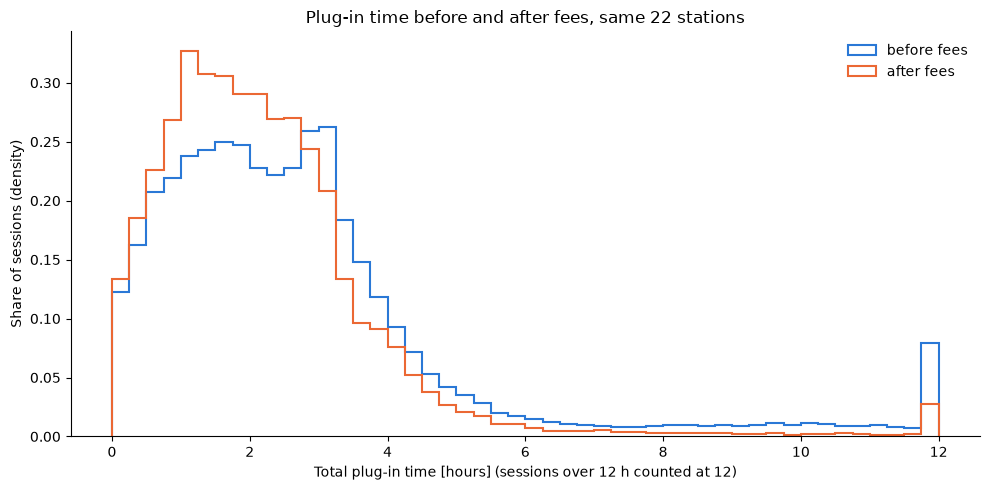

In [37]:
# distribution of plug-in time before and after fees (same stations, 12 months each)
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.arange(0, 12.25, 0.25)
for period, color in [("before fees", "#2a78d6"), ("after fees", "#eb6834")]:
    hours = fee_window.loc[fee_window["period"] == period, "total_duration_hours"]
    ax.hist(hours.clip(upper=12), bins=bins, density=True, histtype="step", linewidth=1.5, color=color, label=period)

ax.set_xlabel("Total plug-in time [hours] (sessions over 12 h counted at 12)")
ax.set_ylabel("Share of sessions (density)")
ax.set_title("Plug-in time before and after fees, same 22 stations")
ax.legend(frameon=False)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

**What the fee changed**

- The fee is charged per kWh: almost every paid session costs about **$0.23 per kWh** (10th–90th percentile $0.229–0.237), and the rate stays the same from 2017 to 2020. The fee per hour varies much more, so time plugged in is not charged directly.
- Comparing the 12 months before and after 1 August 2017 at the same 22 stations:
  - **Sessions per day fell by about 39%** (135 → 82).
  - Sessions got shorter: the median plug-in time fell from 2.3 h to 1.9 h, and the share of sessions over 4 h almost halved (16% → 9%).
  - **Long idling dropped sharply:** sessions idle for more than 30 minutes fell from 26% to 17%, and more than 2 hours from 9.4% to 3.5%. Even though only energy is charged, drivers unplug sooner.
  - The number of different users went *up* (5,028 → 5,715, +14%), but only 2,154 users charged in both periods, and those users charged 41% less often. Heavy users charged less often or left, and more occasional users came.
- **Caveat:** this is a before/after comparison, not a controlled experiment. Other things changed at the same time. In particular, new stations opened nearby (HIGH 2/3 in January 2017, BRYANT 4–6 in July 2017, CAMBRIDGE 3–5 and TED THOMPSON 2–4 in March 2018), which can take sessions away from the stations compared here.

### Energy per session

count    256639.00
mean          8.61
std           7.16
min           0.10
1%            0.35
5%            1.12
25%           3.87
50%           6.91
75%          11.50
95%          20.06
99%          37.02
max          97.36
Name: Energy (kWh), dtype: float64

Charging power [kW] percentiles: {0.01: 1.27, 0.1: 2.79, 0.5: 3.7, 0.9: 6.02, 0.99: 6.21}
Sessions above 7.2 kW (not possible on these Level 2 chargers): 0
Correlation of energy with charging time: 0.87 | with total plug-in time: 0.64
Median energy by time of day: {'Afternoon': 6.3, 'Evening': 6.8, 'Morning': 7.7, 'Night': 6.9}


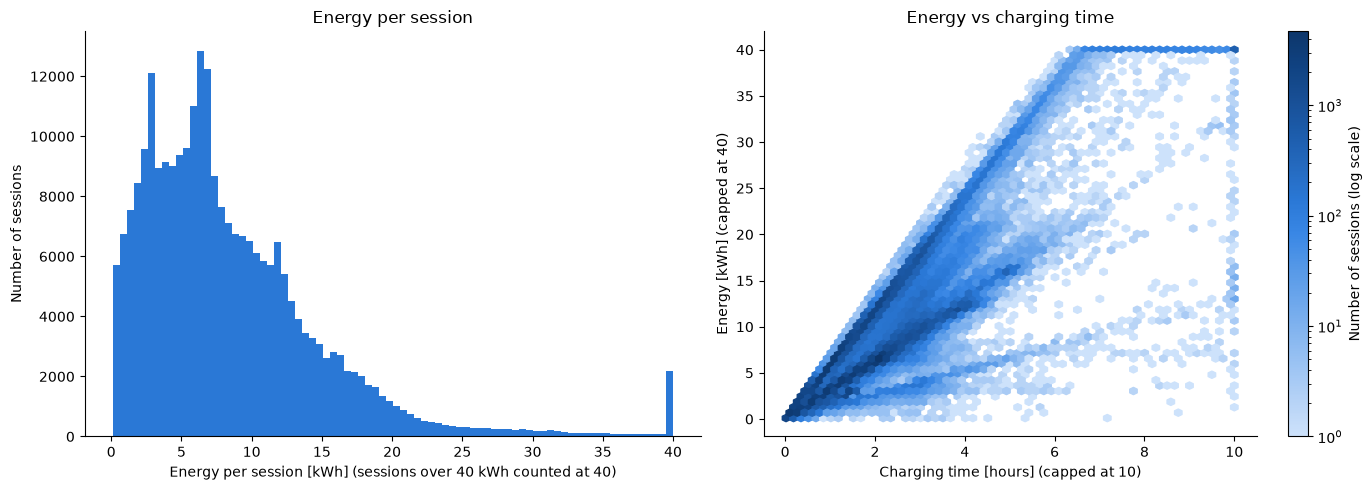

In [38]:
energy = df["Energy (kWh)"]
display(energy.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2))

# average charging power = energy / charging time
power_kw = energy / df["charging_duration_hours"]
print("Charging power [kW] percentiles:", power_kw.quantile([0.01, 0.1, 0.5, 0.9, 0.99]).round(2).to_dict())
print("Sessions above 7.2 kW (not possible on these Level 2 chargers):", (power_kw > 7.2).sum())

print("Correlation of energy with charging time:", round(energy.corr(df["charging_duration_hours"]), 2),
      "| with total plug-in time:", round(energy.corr(df["total_duration_hours"]), 2))
print("Median energy by time of day:", df.groupby("time_of_day")["Energy (kWh)"].median().round(1).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(energy.clip(upper=40), bins=80, color="#2a78d6")
axes[0].set_xlabel("Energy per session [kWh] (sessions over 40 kWh counted at 40)")
axes[0].set_ylabel("Number of sessions")
axes[0].set_title("Energy per session")

hb = axes[1].hexbin(df["charging_duration_hours"].clip(upper=10), energy.clip(upper=40),
                    gridsize=60, cmap=sequential_blue, mincnt=1, bins="log")
fig.colorbar(hb, ax=axes[1], label="Number of sessions (log scale)")
axes[1].set_xlabel("Charging time [hours] (capped at 10)")
axes[1].set_ylabel("Energy [kWh] (capped at 40)")
axes[1].set_title("Energy vs charging time")
for ax in axes:
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()

**Energy per session**

- A typical session delivers **about 7 kWh** (median 6.9 kWh; half of all sessions are between 3.8 and 11.5 kWh). The distribution is right-skewed: 5% of sessions deliver more than 20 kWh, and the largest 97 kWh.
- Energy is driven by **charging time** (correlation 0.87), much less by total plug-in time (0.64), because idle time adds no energy.
- The median charging power is **3.7 kW** and 99% of sessions stay below 6.2 kW, which fits Level 2 chargers and the cars' on-board chargers. The bands in the right plot are cars charging at different power levels. 18 sessions above 7.2 kW are not physically plausible.
- Morning sessions deliver the most energy (median 7.7 kWh), which fits people charging while at work.

### Users

Sessions without a usable User ID: 7,984
Users: 21,332


count
1 session    9409
2-9          8344
10-49        2566
50+          1013
Name: users, dtype: int64

Users with only one session: 44%
Most sessions by a single user: 1,110
Top 1% of users make 31% of the sessions
Top 5% of users make 63% of the sessions
Top 10% of users make 76% of the sessions
Top 20% of users make 86% of the sessions


,sessions,total_h_median,energy_kwh_median,share_idle_over_30min
user_group,,,,
1 session,9409,1.570,6.269,0.125
2-9,31135,1.535,5.858,0.137
10-49,54660,1.685,6.115,0.164
50+,153451,2.439,7.542,0.236


Median number of stations used by users with 10+ sessions: 6.0
Most common driver postal codes: {'94301': 24792, '94303': 22348, '94306': 21367, '94025': 11476, '94043': 7473}


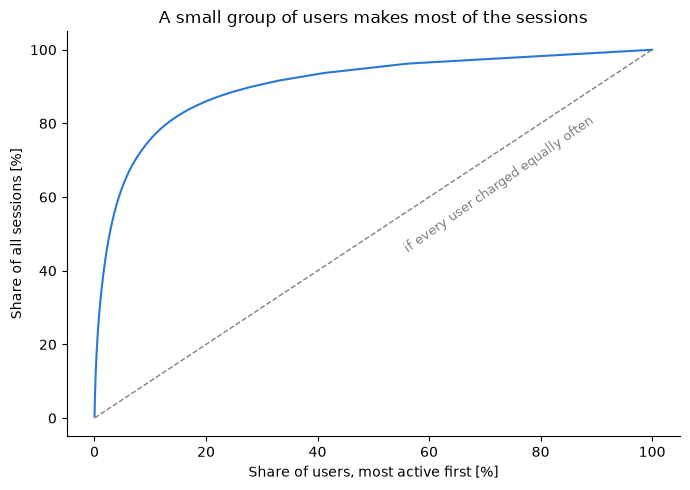

In [39]:
# users with a known ID ('missing' and the placeholder '0' excluded)
known = df[df["User ID"].notna() & ~df["User ID"].isin(["missing", "0"])]
print(f"Sessions without a usable User ID: {len(df) - len(known):,}")

sessions_per_user = known["User ID"].value_counts()
user_group = pd.cut(sessions_per_user, [0, 1, 9, 49, np.inf], labels=["1 session", "2-9", "10-49", "50+"])
print(f"Users: {len(sessions_per_user):,}")
display(user_group.value_counts().sort_index().rename("users"))
print(f"Users with only one session: {(sessions_per_user == 1).mean():.0%}")
print(f"Most sessions by a single user: {sessions_per_user.max():,}")

for share in [0.01, 0.05, 0.10, 0.20]:
    top = sessions_per_user.nlargest(int(len(sessions_per_user) * share)).sum() / sessions_per_user.sum()
    print(f"Top {share:.0%} of users make {top:.0%} of the sessions")

# behaviour by user group
display(
    known.assign(user_group=known["User ID"].map(user_group))
    .groupby("user_group", observed=True)
    .agg(sessions=("Energy (kWh)", "size"),
         total_h_median=("total_duration_hours", "median"),
         energy_kwh_median=("Energy (kWh)", "median"),
         share_idle_over_30min=("idle_hours", lambda s: (s > 0.5).mean()))
    .round(3)
)

stations_per_user = known.groupby("User ID")["Station Name"].nunique()
print("Median number of stations used by users with 10+ sessions:", stations_per_user[sessions_per_user >= 10].median())
postal = known["Driver Postal Code"]
print("Most common driver postal codes:", postal[postal.notna() & (postal != "missing")].value_counts().head(5).to_dict())

# concentration curve: share of sessions made by the top x% of users
cumulative = sessions_per_user.sort_values(ascending=False).cumsum() / sessions_per_user.sum()
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(np.arange(1, len(cumulative) + 1) / len(cumulative) * 100, cumulative.values * 100, color="#2a78d6", linewidth=1.5)
ax.plot([0, 100], [0, 100], "--", color="gray", linewidth=1)
ax.text(55, 45, "if every user charged equally often", color="gray", fontsize=9, rotation=35)
ax.set_xlabel("Share of users, most active first [%]")
ax.set_ylabel("Share of all sessions [%]")
ax.set_title("A small group of users makes most of the sessions")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

**Users**

- About 21,400 users have a usable ID. Around 8,000 sessions have no User ID or the placeholder `0`.
- **Usage is very concentrated:** 44% of users charged only once, while the top 10% of users make 76% of all sessions (the top 1% alone make 31%). The most active user has over 1,100 sessions.
- **Regular users behave differently.** Users with 50+ sessions stay plugged in longer (median 2.4 h vs about 1.5 h), take more energy (7.5 vs about 6 kWh), and **leave their car idle for more than 30 minutes much more often (24% vs 13%)**. Long idling is mainly a habit of regular users, which matters for any policy against blocking chargers.
- Regular users are not tied to one station: users with 10+ sessions used a median of 6 different stations.
- Most drivers are local or commute from nearby: the most common home postal codes are 94301, 94303 and 94306 (Palo Alto), 94025 (Menlo Park) and 94043 (Mountain View). The place names are general knowledge of US postal codes; the dataset only contains the codes.
- These differences between users are what the clustering in Section 2 should pick up.

### When do sessions start? Weekday × hour

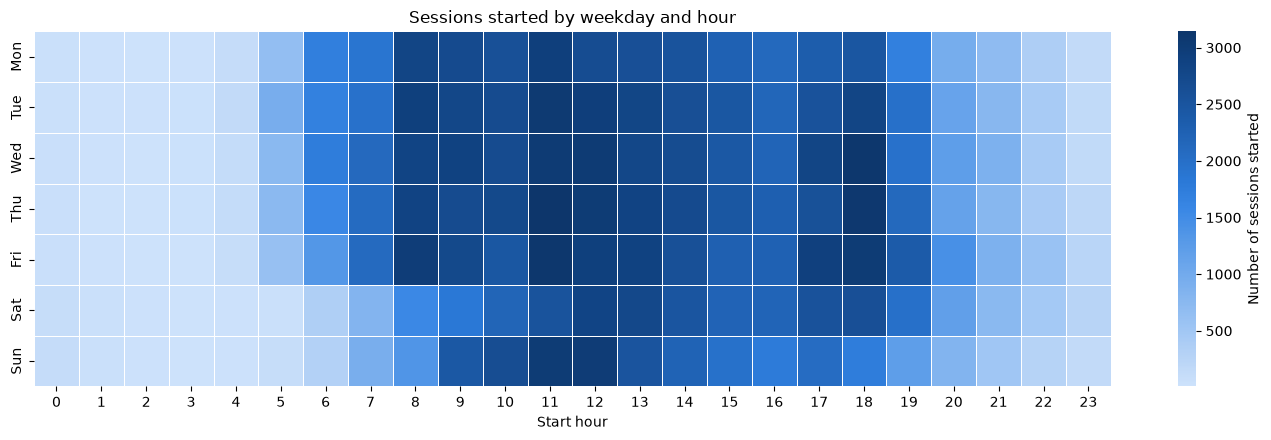

Busiest start hour per day: {'Mon': 11, 'Tue': 11, 'Wed': 18, 'Thu': 11, 'Fri': 11, 'Sat': 12, 'Sun': 11}
Busiest weekday-hour combinations: {'Thu 11:00': 3144, 'Fri 11:00': 3118, 'Wed 18:00': 3109, 'Thu 18:00': 3094, 'Tue 11:00': 3055}
Sessions starting before 8:00 - weekdays: 11.8% | weekends: 4.9%
Sessions starting between 0:00 and 4:59: 0.6%


start_hour,5,6,8,11,12,18
Mon,656,1714,2825,2944,2674,2475
Tue,944,1674,2926,3055,2956,2821
Wed,746,1752,2840,3024,3028,3109
Thu,735,1572,2857,3144,3018,3094
Fri,615,1341,2981,3118,2934,3011
Sat,56,354,1562,2537,2830,2611
Sun,95,325,1356,3011,2998,1744


In [40]:
starts = df.groupby(["day_of_week", "start_hour"]).size().unstack(fill_value=0)
starts.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(starts, cmap=sequential_blue, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Number of sessions started"}, ax=ax)
ax.set_xlabel("Start hour")
ax.set_ylabel("")
ax.set_title("Sessions started by weekday and hour")
plt.tight_layout()
plt.show()

print("Busiest start hour per day:", starts.idxmax(axis=1).to_dict())
busiest = starts.stack().sort_values(ascending=False).head(5)
print("Busiest weekday-hour combinations:", {f"{day} {hour}:00": n for (day, hour), n in busiest.items()})

weekend = starts.index.isin(["Sat", "Sun"])
print(f"Sessions starting before 8:00 - weekdays: {starts.loc[~weekend, :7].sum().sum() / starts.loc[~weekend].sum().sum():.1%}"
      f" | weekends: {starts.loc[weekend, :7].sum().sum() / starts.loc[weekend].sum().sum():.1%}")
print(f"Sessions starting between 0:00 and 4:59: {starts.loc[:, :4].sum().sum() / starts.sum().sum():.1%}")
display(starts[[5, 6, 8, 11, 12, 18]])

**Start times**

- On weekdays there are **three peaks**: around 8:00 (arriving at work), 11:00–12:00, and 18:00. The busiest hour of the week is Thursday 11:00, closely followed by Wednesday 18:00; from Tuesday to Friday the evening is nearly as busy as midday.
- Weekday sessions start early: 12% of them start before 8:00, compared with 5% at weekends, which fits commuters.
- On weekends the busiest time is 11:00–12:00. Sunday has no real evening peak (about 1,800 sessions at 18:00 vs about 3,000 at 11:00).
- Almost no sessions start between midnight and 5:00 (0.6%).

### How busy are the stations?

The session counts above do not show how full the stations are. Here we check, for every hour of 2019, what share of each station's ports was occupied (a car plugged in). We use 2019 because it is the last full year before COVID, and only the stations that were running the whole year.

Stations: 33


,ports,avg_share_occupied,weekday_12h_share_occupied,weekday_12h_share_full
WEBSTER 1,2,0.37,0.77,0.59
WEBSTER 2,2,0.30,0.75,0.57
HIGH 3,2,0.29,0.73,0.56
TED THOMPSON 1,2,0.25,0.72,0.54
BRYANT 6,2,0.27,0.70,0.52
HAMILTON 2,2,0.44,0.70,0.52
HIGH 2,2,0.25,0.69,0.50
WEBSTER 3,2,0.25,0.67,0.48
BRYANT 5,2,0.24,0.66,0.46
BRYANT 4,2,0.18,0.66,0.49


Average share of ports occupied [%] at selected hours:


,Weekday,Weekend
3,2.6,3.2
8,15.8,8.9
12,48.3,28.5
13,45.9,29.6
19,30.8,21.3


Peak hour: {'Weekday': 12, 'Weekend': 13} | peak share [%]: {'Weekday': 48.3, 'Weekend': 29.6}
Stations with all ports taken at noon on at least 45% of weekdays (12): ['WEBSTER 1', 'WEBSTER 2', 'HIGH 3', 'TED THOMPSON 1', 'BRYANT 6', 'HAMILTON 2', 'HIGH 2', 'WEBSTER 3', 'BRYANT 5', 'BRYANT 4', 'MPL 6', 'MPL 5']


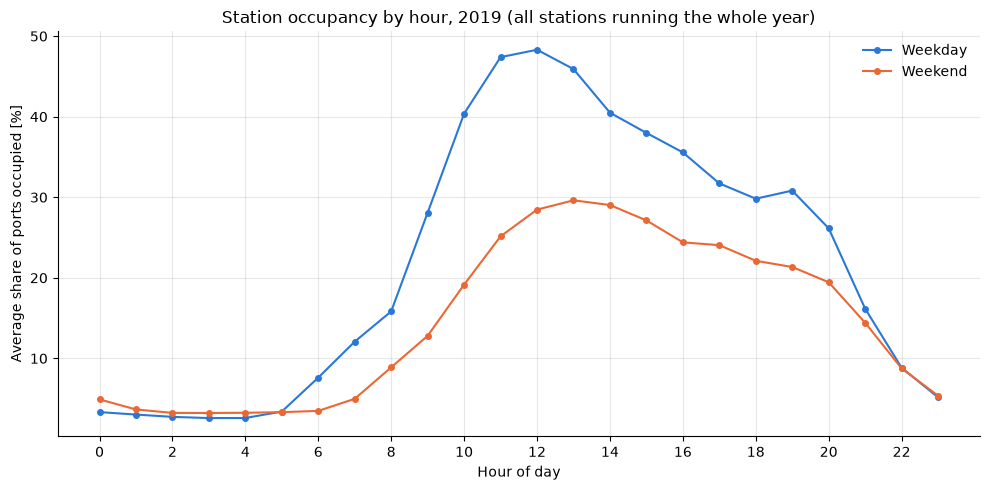

In [41]:
year_start, year_end = pd.Timestamp("2019-01-01"), pd.Timestamp("2020-01-01")
station_span = df.groupby("Station Name")["Start Date"].agg(["min", "max"])
stations_2019 = station_span[(station_span["min"] < year_start) & (station_span["max"] >= "2019-12-31")].index
ports = df.groupby("Station Name")["Port Number"].nunique()
hours = pd.date_range(year_start, year_end, freq="h", inclusive="left")

# share of ports occupied at the start of every hour: sessions started so far minus sessions ended so far
occupancy = {}
for station in stations_2019:
    s = df[df["Station Name"] == station]
    started = np.searchsorted(np.sort(s["Start Date"].values), hours.values, side="right")
    ended = np.searchsorted(np.sort(s["End Date"].values), hours.values, side="right")
    occupancy[station] = np.minimum((started - ended) / ports[station], 1)
occupancy = pd.DataFrame(occupancy, index=hours)
print("Stations:", occupancy.shape[1])

station_util = pd.DataFrame({
    "ports": ports[stations_2019],
    "avg_share_occupied": occupancy.mean(),
    "weekday_12h_share_occupied": occupancy[(occupancy.index.dayofweek < 5) & (occupancy.index.hour == 12)].mean(),
    "weekday_12h_share_full": (occupancy[(occupancy.index.dayofweek < 5) & (occupancy.index.hour == 12)] == 1).mean(),
}).sort_values("weekday_12h_share_occupied", ascending=False)
display(station_util.round(2).head(12))

# average share of ports occupied by hour of day, weekdays vs weekends
profile = occupancy.mean(axis=1).groupby([np.where(occupancy.index.dayofweek < 5, "Weekday", "Weekend"), occupancy.index.hour]).mean().unstack(0)
print("Average share of ports occupied [%] at selected hours:")
display((profile.loc[[3, 8, 12, 13, 19]] * 100).round(1))
print("Peak hour:", profile.idxmax().to_dict(), "| peak share [%]:", (profile.max() * 100).round(1).to_dict())

often_full = station_util[station_util["weekday_12h_share_full"] >= 0.45]
print(f"Stations with all ports taken at noon on at least 45% of weekdays ({len(often_full)}):", list(often_full.index))
fig, ax = plt.subplots(figsize=(10, 5))
for day_type, color in [("Weekday", "#2a78d6"), ("Weekend", "#eb6834")]:
    ax.plot(profile.index, profile[day_type] * 100, color=color, linewidth=1.5, marker="o", markersize=4, label=day_type)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Average share of ports occupied [%]")
ax.set_title("Station occupancy by hour, 2019 (all stations running the whole year)")
ax.legend(frameon=False)
ax.grid(True, alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

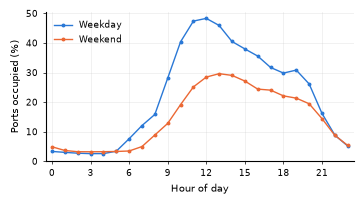

In [58]:
# for a report
small_fonts = {"font.size": 7, "axes.labelsize": 7, "xtick.labelsize": 6.5,
               "ytick.labelsize": 6.5, "legend.fontsize": 6.5}

with plt.rc_context(small_fonts):
    fig, ax = plt.subplots(figsize=(3.5, 1.9))
    for day_type, color in [("Weekday", "#2a78d6"), ("Weekend", "#eb6834")]:
        ax.plot(profile.index, profile[day_type] * 100, color=color, lw=1,
                marker="o", ms=1.8, label=day_type)
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlim(-0.5, 23.5)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Ports occupied (%)")
    ax.legend(frameon=False, loc="upper left")
    ax.grid(True, alpha=0.3, lw=0.4)
    ax.tick_params(length=2, width=0.5)
    sns.despine(ax=ax)

    fig.tight_layout(pad=0.3)
    fig.savefig("figures/occupancy_by_hour.pdf", bbox_inches="tight")
    plt.show()

**Station occupancy (2019)**

- At night almost all ports are free (about 3% occupied). On weekdays occupancy rises quickly from 8:00 and peaks at **48% of all ports at noon**. A smaller second rise comes around 19:00 (31%). On weekends the peak is lower (30% at 13:00).
- The busiest stations are often full at midday. At WEBSTER 1, a port is occupied 77% of the time at weekday noon, and **both ports are taken on 59% of weekdays at noon**. 12 stations have all ports taken at noon on at least 45% of weekdays: WEBSTER 1–3, HIGH 2/3, TED THOMPSON 1, BRYANT 4–6, HAMILTON 2, and the single-port MPL 5 and MPL 6.
- So the network as a whole has spare capacity, but the downtown stations are a bottleneck at weekday midday. Combined with idle time, this shows where blocked chargers cost the most: a car left plugged in after charging at WEBSTER 1 at noon very likely keeps someone else from charging.

(Merge 2 plots for the report)

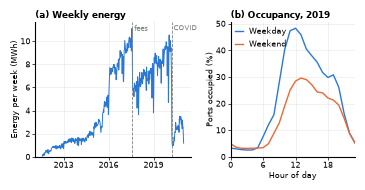

In [53]:
import matplotlib.dates as mdates

tiny_fonts = {"font.size": 6, "axes.titlesize": 6.5, "axes.titleweight": "bold",
              "axes.labelsize": 6, "xtick.labelsize": 5.5, "ytick.labelsize": 5.5,
              "legend.fontsize": 5.5, "axes.titlepad": 3}

with plt.rc_context(tiny_fonts):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(3.5, 1.75), gridspec_kw={"width_ratios": [1.25, 1]})

    # (a) weekly energy, whole period
    ax1.plot(weekly_energy.index, weekly_energy.values / 1000, color="#2a78d6", lw=0.7)
    for date, name in [("2017-08-01", "fees"), ("2020-03-16", "COVID")]:
        ax1.axvline(pd.Timestamp(date), ls="--", c="grey", lw=0.6)
        ax1.text(pd.Timestamp(date), 0.98, f" {name}", transform=ax1.get_xaxis_transform(),
                 va="top", ha="left", fontsize=5, color="grey")
    ax1.xaxis.set_major_locator(mdates.YearLocator(3))
    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax1.set_ylim(bottom=0)
    ax1.set_ylabel("Energy per week (MWh)", labelpad=1)
    ax1.set_title("(a) Weekly energy", loc="left")

    # (b) occupancy by hour, 2019
    for day_type, color in [("Weekday", "#2a78d6"), ("Weekend", "#eb6834")]:
        ax2.plot(profile.index, profile[day_type] * 100, color=color, lw=1, label=day_type)
    ax2.set_xticks(range(0, 24, 6))
    ax2.set_xlim(0, 23)
    ax2.set_ylim(bottom=0)
    ax2.set_xlabel("Hour of day", labelpad=1)
    ax2.set_ylabel("Ports occupied (%)", labelpad=1)
    ax2.set_title("(b) Occupancy, 2019", loc="left")
    ax2.legend(frameon=False, loc="upper left", handlelength=1, borderaxespad=0.2)

    for ax in (ax1, ax2):
        ax.grid(True, alpha=0.3, lw=0.4)
        ax.tick_params(length=2, width=0.5, pad=1.5)
        sns.despine(ax=ax)

    fig.tight_layout(pad=0.3, w_pad=0.8)
    fig.savefig("figures/usage_over_time.pdf", bbox_inches="tight")
    plt.show()

### Outliers

How many sessions are extreme, and do they change the averages used above?

In [42]:
very_long = df["total_duration_hours"] > 24
very_short = df["total_duration_hours"] < 2 / 60
almost_no_energy = df["Energy (kWh)"] < 0.1
too_powerful = df["Energy (kWh)"] / df["charging_duration_hours"] > 7.2
flagged = very_long | very_short | almost_no_energy | too_powerful

display(pd.Series({
    "plugged in > 24 h": very_long.sum(),
    "plugged in < 2 min": very_short.sum(),
    "energy < 0.1 kWh": almost_no_energy.sum(),
    "charging power > 7.2 kW": too_powerful.sum(),
    "any of these": flagged.sum(),
}, name="sessions"))
print(f"Share of all sessions: {flagged.mean():.2%}")
print("Both shorter than 2 min and below 0.1 kWh:", (very_short & almost_no_energy).sum())
print(f"Longest session: {df['total_duration_hours'].max():.1f} h")
print("How the short / near-zero sessions ended:", df.loc[very_short | almost_no_energy, "Ended By"].value_counts().head(3).to_dict())

# effect on the averages
cols = ["total_duration_hours", "charging_duration_hours", "idle_hours", "Energy (kWh)"]
display(pd.DataFrame({
    "mean (all)": df[cols].mean(),
    "mean (without flagged)": df.loc[~flagged, cols].mean(),
    "median (all)": df[cols].median(),
    "median (without flagged)": df.loc[~flagged, cols].median(),
}).round(3))

plugged in > 24 h          22
plugged in < 2 min          0
energy < 0.1 kWh            0
charging power > 7.2 kW     0
any of these               22
Name: sessions, dtype: int64

Share of all sessions: 0.01%
Both shorter than 2 min and below 0.1 kWh: 0
Longest session: 114.5 h
How the short / near-zero sessions ended: {}


,mean (all),mean (without flagged),median (all),median (without flagged)
total_duration_hours,2.501,2.497,2.103,2.103
charging_duration_hours,2.014,2.014,1.831,1.831
idle_hours,0.488,0.484,0.007,0.007
Energy (kWh),8.610,8.608,6.911,6.910


### Map of the stations

Use the layer control (top right): the round buttons switch the colouring (street, sessions per active day, idle > 30 min, weekday noon occupancy 2019), and the legend (bottom left) changes with it. Marker size always shows the total number of sessions. The checkboxes add a heatmap and one layer per year. Hover over a station for details.

In [43]:
# one row per station, built from the cleaned df so the map matches the analysis above
map_stations = df.groupby("Station Name")["Start Date"].agg(first_session="min", last_session="max", sessions="size")

# location: the station's most common coordinate pair (stations that moved are shown at their main location, see "Do stations change address or location over time?")
location_counts = df.groupby(["Station Name", "Latitude", "Longitude"]).size().rename("n").reset_index()
main_location = location_counts.loc[location_counts.groupby("Station Name")["n"].idxmax()].set_index("Station Name")
map_stations[["lat", "lon"]] = main_location[["Latitude", "Longitude"]]

map_stations["street"] = map_stations.index.str.replace(r"\s*\d+$", "", regex=True).map(STREET)   # same streets as the station chart
map_stations["ports"] = df.groupby("Station Name")["Port Number"].nunique()
map_stations["sessions_per_day"] = map_stations["sessions"] / ((map_stations["last_session"] - map_stations["first_session"]).dt.days + 1)
map_stations["share_idle_over_30min"] = df.groupby("Station Name")["idle_hours"].apply(lambda s: (s > 0.5).mean())
map_stations["median_energy_kwh"] = df.groupby("Station Name")["Energy (kWh)"].median()
map_stations["noon_occupancy_2019"] = station_util["weekday_12h_share_occupied"]   # from the occupancy analysis (stations running all of 2019)

print(f"{len(map_stations)} stations, {map_stations['sessions'].sum():,} sessions")
display(map_stations.sort_values("sessions_per_day", ascending=False).head(10)
        .round({"lat": 4, "lon": 4, "sessions_per_day": 2, "share_idle_over_30min": 3, "median_energy_kwh": 1, "noon_occupancy_2019": 3}))

46 stations, 256,639 sessions


,first_session,last_session,sessions,lat,lon,street,ports,sessions_per_day,share_idle_over_30min,median_energy_kwh,noon_occupancy_2019
Station Name,,,,,,,,,,,
WEBSTER 1,2015-07-29 13:59:00,2020-12-31 17:49:00,14310,37.4483,-122.1583,Webster St,2,7.22,0.235,7.9,0.766
HAMILTON 2,2011-08-02 12:26:00,2020-11-04 04:54:00,23496,37.4447,-122.1603,Hamilton Ave,2,6.95,0.210,6.7,0.701
WEBSTER 2,2015-07-29 16:53:00,2020-12-30 17:57:00,12559,37.4482,-122.1582,Webster St,2,6.34,0.259,8.1,0.745
CAMBRIDGE 1,2016-01-14 11:19:00,2020-12-31 06:50:00,11070,37.4262,-122.1461,Cambridge Ave,2,6.11,0.186,6.0,0.542
WEBSTER 3,2016-01-14 13:22:00,2020-12-31 14:19:00,10417,37.4483,-122.1582,Webster St,2,5.74,0.239,8.1,0.674
HIGH 3,2017-01-06 18:40:00,2020-12-31 11:19:00,8253,37.4434,-122.1631,High St,2,5.67,0.170,7.1,0.730
TED THOMPSON 1,2016-01-14 10:28:00,2020-10-11 10:06:00,9738,37.4283,-122.1442,Cambridge Ave,2,5.62,0.218,7.7,0.722
HIGH 1,2015-07-29 15:51:00,2020-12-31 09:37:00,10663,37.4436,-122.1628,High St,2,5.38,0.223,7.6,0.563
CAMBRIDGE 2,2016-01-14 13:45:00,2020-12-29 09:06:00,9159,37.4262,-122.1461,Cambridge Ave,2,5.06,0.194,6.0,0.450


In [52]:
import folium
from branca.colormap import LinearColormap
from branca.element import MacroElement, Template
from folium.plugins import HeatMap

BLUES = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]   # light to dark blue, all visible on the map tiles
NO_DATA = "#c3c2b7"
MAX_SESSIONS = map_stations["sessions"].max()


def radius(n, max_n=MAX_SESSIONS):
    """Marker radius in pixels: area grows with the number of sessions."""
    return 3 + 10 * np.sqrt(n / max_n)


def tooltip(name, row):
    noon = "no full-year 2019 data" if pd.isna(row["noon_occupancy_2019"]) else f"{row['noon_occupancy_2019']:.0%}"
    return (f"<b>{name}</b> ({row['street']})<br>"
            f"In use: {row['first_session']:%b %Y} – {row['last_session']:%b %Y}, {row['ports']} port(s)<br>"
            f"Sessions: {row['sessions']:,} ({row['sessions_per_day']:.1f} per active day)<br>"
            f"Idle > 30 min: {row['share_idle_over_30min']:.0%} of sessions<br>"
            f"Median energy: {row['median_energy_kwh']:.1f} kWh<br>"
            f"Weekday noon occupancy 2019: {noon}")


centre = np.average(map_stations[["lat", "lon"]], axis=0, weights=map_stations["sessions"]).tolist()
m = folium.Map(location=centre, zoom_start=14, tiles=None)
m_sites = folium.Map(
    location=centre, zoom_start=15,
    tiles="https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png",
    attr="&copy; OpenStreetMap contributors &copy; CARTO",
)
folium.TileLayer("OpenStreetMap", control=False).add_to(m)   # base map, no API key needed

# metric layers are radio buttons: only one colouring is visible at a time, and the legend follows it
metric_layers = {
    "Street": None,
    "Sessions per active day": ("sessions_per_day", "{:.1f}"),
    "Sessions idle > 30 min": ("share_idle_over_30min", "{:.0%}"),
    "Weekday noon occupancy (2019)": ("noon_occupancy_2019", "{:.0%}"),
}
legend_blocks = {}
for i, (layer_name, metric) in enumerate(metric_layers.items()):
    layer = folium.FeatureGroup(name=layer_name, overlay=False, show=(i == 0))
    if metric is not None:
        column, fmt = metric
        cmap = LinearColormap(BLUES, vmin=map_stations[column].min(), vmax=map_stations[column].max())
    for name, row in map_stations.sort_values("sessions", ascending=False).iterrows():   # big markers first, small ones on top
        if metric is None:
            fill = STREET_COLORS[row["street"]]
        else:
            fill = NO_DATA if pd.isna(row[column]) else cmap(row[column])
        folium.CircleMarker(
            location=(row["lat"], row["lon"]), radius=radius(row["sessions"]),
            color="white", weight=1.5, fill=True, fill_color=fill, fill_opacity=0.9,
            tooltip=folium.Tooltip(tooltip(name, row)),
        ).add_to(layer)
    layer.add_to(m)

    # legend text for this layer
    if metric is None:
        items = "".join(f'<div><span class="dot" style="background:{color}"></span>{street}</div>'
                        for street, color in STREET_COLORS.items())
        legend_blocks[layer_name] = f"<b>Colour: street</b>{items}"
    else:
        low, high = map_stations[column].min(), map_stations[column].max()
        no_data = (f'<div><span class="dot" style="background:{NO_DATA}"></span>no data (not running all of 2019)</div>'
                   if map_stations[column].isna().any() else "")
        legend_blocks[layer_name] = (
            f"<b>Colour: {layer_name.lower()}</b>"
            f'<div class="bar" style="background:linear-gradient(to right, {", ".join(BLUES)})"></div>'
            f'<div class="ticks"><span>{fmt.format(low)}</span><span>{fmt.format(high)}</span></div>{no_data}'
        )

# overlays (checkboxes): heatmap and one layer per year
HeatMap(map_stations[["lat", "lon", "sessions"]].values.tolist(), name="Heatmap of sessions",
        radius=25, blur=20, show=False).add_to(m)
yearly = df.groupby(["year", "Station Name"]).size().rename("n").reset_index().join(map_stations[["lat", "lon"]], on="Station Name")
max_yearly = yearly["n"].max()
for year, sub in yearly.groupby("year"):
    layer = folium.FeatureGroup(name=f"Sessions in {year}", show=False)
    for _, row in sub.iterrows():
        folium.CircleMarker(
            location=(row["lat"], row["lon"]), radius=radius(row["n"], max_yearly),
            color="white", weight=1, fill=True, fill_color="#eb6834", fill_opacity=0.8,
            tooltip=f"{row['Station Name']}: {row['n']:,} sessions in {year}",
        ).add_to(layer)
    layer.add_to(m)

folium.Marker(centre, tooltip="Usage-weighted centre of the stations", icon=folium.Icon(color="gray", icon="star")).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)

# size key: example circles drawn with the same radius function as the markers
size_examples = [1_000, 5_000, 20_000]
size_key = "".join(
    f'<div class="size"><svg width="{2 * radius(n) + 4:.0f}" height="{2 * radius(n) + 4:.0f}">'
    f'<circle cx="{radius(n) + 2:.1f}" cy="{radius(n) + 2:.1f}" r="{radius(n):.1f}" fill="#e1e0d9" stroke="#898781"/></svg>'
    f"<span>{n:,}</span></div>" for n in size_examples
)

legend = MacroElement()
legend._template = Template("""
{% macro html(this, kwargs) %}
<style>
  .map-legend {position: absolute; bottom: 24px; left: 12px; z-index: 9999; background: rgba(255,255,255,0.95);
               padding: 10px 12px; border-radius: 6px; box-shadow: 0 1px 4px rgba(0,0,0,0.25);
               font: 12px system-ui, -apple-system, "Segoe UI", sans-serif; color: #0b0b0b; max-width: 240px;}
  .map-legend .dot {display: inline-block; width: 10px; height: 10px; border-radius: 50%; margin-right: 6px; vertical-align: middle;}
  .map-legend .bar {height: 10px; border-radius: 3px; margin: 6px 0 2px;}
  .map-legend .ticks {display: flex; justify-content: space-between; color: #52514e;}
  .map-legend .sizes {display: flex; align-items: flex-end; gap: 10px; margin-top: 4px;}
  .map-legend .size {display: flex; flex-direction: column; align-items: center; color: #52514e;}
  .map-legend hr {border: none; border-top: 1px solid #e1e0d9; margin: 8px 0;}
  .map-legend .note {color: #52514e; margin-top: 6px;}
</style>
<div class="map-legend">
  """ + "".join(
      f'<div class="legend-block" data-layer="{name}" style="display:{"block" if i == 0 else "none"}">{block}</div>'
      for i, (name, block) in enumerate(legend_blocks.items())
  ) + f"""
  <hr><b>Size: total sessions</b>
  <div class="sizes">{size_key}</div>
  <div class="note">Orange circles (year layers): sessions in that year.<br>Star: usage-weighted centre.</div>
</div>
{{% endmacro %}}
{{% macro script(this, kwargs) %}}
  {{{{ this._parent.get_name() }}}}.on("baselayerchange", function (e) {{
    document.querySelectorAll(".map-legend .legend-block").forEach(function (el) {{
      el.style.display = el.dataset.layer === e.name ? "block" : "none";
    }});
  }});
{{% endmacro %}}
""")
m.add_child(legend)

# also save the map as a standalone page: if it does not show in the notebook, open this file in a browser
from pathlib import Path
map_path = Path("outputs/geospatial/station_map_main.html")
map_path.parent.mkdir(parents=True, exist_ok=True)
m.get_root().header.add_child(folium.Element(
    "<style>* {-webkit-print-color-adjust: exact !important; print-color-adjust: exact !important;}</style>"
))
m.save(map_path)
print(f"Map saved to {map_path.resolve()}")
m

Map saved to C:\Users\rogal\MojGithub\Intro-to-Business-Analytics\outputs\geospatial\station_map_main.html
